# Preprocessing the SOFC logger data: stage-detection sensors only

Only the sensors that the stage detection (`operating_states.load_signals`) reads are used here:

| Signal in the stage rules | Columns |
|---|---|
| Stack temperature (median / min / max) | `TIR_4_6_1` … `TIR_4_6_36` (36 stack thermocouples) |
| Ambient proxy (Shut-down "at ambient" rule) | `TIR_1_1_1`, `TIR_1_2_1`, `TIR_1_3`, `TIR_1_4_1` |
| Cathode inlet / EAPH outlet temperature | `TIRC_2_06` |
| Air on (stack inlet pressure) | `PIR_2_02` |
| EAPH heater on | `EIRC_2_01_ActV_In_ThreePhasePower` |
| String load current and voltage (load on, stack power) | `PLC_hostSetp_ctrl_ctEIRC4s_rCurrMonitor`, `_rVoltMonitor`, s = 1…5 |

That is 53 columns (`STAGE_COLS`). Every other TIR / PIR / FIRC / EIRC column is left out.

Two copies of the day files are used:
* **raw**: `../02_data/raw/<yyyymmdd>.txt`, the logger exports as delivered. The column set grows over time
  (467 → 826 columns) and a few files switch to a wider row format in the middle of the day.
* **common**: `../02_data/common/<yyyymmdd>.txt`, the same rows restricted to the 466 columns that exist in every raw file.

Both are tab-separated, decimal comma, 1 Hz.

Steps:
1. **Raw data inventory** (raw): columns per file and how the header changes over time; rows, and blank cells and `-1` codes in the stage columns, per file and per column.
2. **Common column inventory** (common): check that every day file has the same header and that it holds all stage columns.
3. **Per-column statistics** (common): min, max, distinct values, NaN count and `-1` count for each day.
4. **Classification**: label every stage column as *all NaN*, *constant*, *few values* or *varying*, and flag faulty sensors.
5. **Column selection**: keep the stage columns with status *varying*.
6. **Cleaning and export**: turn the `-1` code into NaN, add the string power (EIRC4.s V × I), resample, and write one parquet file per day.

Outputs go to `../02_data/preprocessed_stage/` (parquet) and `preprocessing/stage/` (reports, column groups).
The full-sensor outputs in `../02_data/preprocessed/` and `preprocessing/column_groups.json` are left alone,
because `04_synthetic_data/build_library.py` uses them for its all-sensor rebuild check.

In [1]:
import re
import time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.csv as pv

import sys
sys.path.insert(0, "scripts")   # helper modules live in 03_data_analysis/scripts/
import operating_states as ops

pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 200)

RAW = Path("../02_data/raw")        # logger exports, column set grows over time
SRC = Path("../02_data/common")     # same rows, only the columns present in every raw file
OUT = Path("../02_data/preprocessed_stage")      # stage-sensor export (full set stays in preprocessed/)
REPORT = Path("preprocessing/stage")               # reports and column groups of this notebook
STATS_CACHE = Path("preprocessing/column_stats_per_day.parquet")   # shared cache, may hold more columns

SENTINEL = -1.0        # logger's code for a missing reading
FEW_VALUES = 5         # <= this many distinct values counts as "few values" (flags, step setpoints)
RESAMPLE = "10s"       # resample rule for the cleaned export (None keeps 1 Hz)
N_THREADS = 8
LOAD_ON_A = 1.0       # string load current above this counts as "load on" (off-days read < 0.01 A)

# Sensors read by operating_states.load_signals (keep in step with that function)
STAGE_COLS = (
    [f"TIR_4_6_{i}" for i in range(1, 37)]                       # stack thermocouples -> T_stack
    + ops.AMB_COLS                                                # ambient proxy -> T_amb
    + ["TIRC_2_06",                                               # cathode inlet / EAPH outlet
       "PIR_2_02",                                                # stack inlet air pressure -> air on
       "EIRC_2_01_ActV_In_ThreePhasePower"]                       # EAPH heater power -> heater on
    + [f"PLC_hostSetp_ctrl_ctEIRC4{s}_r{q}Monitor" for s in range(1, 6) for q in ("Curr", "Volt")]   # string loads
)
STAGE_SET = set(STAGE_COLS)

FAMILY_RE = re.compile(r"^(TIRZ|TIRC|TIR|PIRZ|PIR)_")


def family(col):
    if "FIRC" in col:
        return "FIRC"
    if "EIRC" in col:
        return "EIRC"
    m = FAMILY_RE.match(col)
    return m.group(1) if m else None


def fmt_day(day):
    """'20260330' -> '30 Mar 2026'"""
    return pd.to_datetime(day, format="%Y%m%d").strftime("%d %b %Y")


raw_files = sorted(RAW.glob("*.txt"))
files = sorted(SRC.glob("*.txt"))
REPORT.mkdir(parents=True, exist_ok=True)
print(f"{len(STAGE_COLS)} stage columns")
print(f"raw: {len(raw_files)} day files, {sum(f.stat().st_size for f in raw_files) / 1e9:.1f} GB | "
      f"common: {len(files)} day files, {sum(f.stat().st_size for f in files) / 1e9:.1f} GB")

53 stage columns
raw: 39 day files, 15.4 GB | common: 39 day files, 12.0 GB


## 1. Raw data: files, columns, rows and missing values

The raw files are the logger exports as delivered. Over the campaign the logger configuration was extended several
times, so later files have more columns than earlier ones, and the new columns are inserted in the middle of the header,
not appended at the end.


### 1.1 Column inventory of the raw files

Which columns exist in each file, when columns were added or removed, and which columns are present in every file
(those make up the common dataset used from section 2 on).


In [2]:
def read_header(path):
    with open(path, encoding="latin-1") as fh:
        return fh.readline().rstrip("\r\n").split("\t")


raw_headers = {f.stem: read_header(f)[1:] for f in raw_files}        # column names without "Date Time"
HEADER_BY_COUNT = {len(h): h for h in raw_headers.values()}          # every column count maps to exactly one header
assert all(raw_headers[d] == HEADER_BY_COUNT[len(raw_headers[d])] for d in raw_headers)

raw_cols = list(dict.fromkeys(c for h in raw_headers.values() for c in h))    # union of all headers, in file order
in_every_file = set.intersection(*map(set, raw_headers.values()))
print(f"{len(raw_cols)} distinct columns over {len(raw_files)} raw files, {len(in_every_file)} of them present in every file")

# Day-to-day header changes
rows, prev = [], None
for day, h in raw_headers.items():
    added = [c for c in h if c not in set(prev)] if prev is not None else []
    removed = [c for c in prev if c not in set(h)] if prev is not None else []
    rows.append({"day": day, "date": fmt_day(day), "columns": len(h), "added": len(added), "removed": len(removed),
                 "size_MB": round((RAW / f"{day}.txt").stat().st_size / 1e6),
                 "example": ", ".join((added or removed)[:3]) + (" ..." if len(added or removed) > 3 else "")})
    prev = h
header_changes = pd.DataFrame(rows)
header_changes[(header_changes["added"] > 0) | (header_changes["removed"] > 0) | (header_changes.index == 0)]


835 distinct columns over 39 raw files, 466 of them present in every file


,day,date,columns,added,removed,size_MB,example
0,20251030,30 Oct 2025,466,0,0,305,
1,20251113,13 Nov 2025,467,1,0,302,PT02_Haug
15,20260213,13 Feb 2026,472,5,0,300,"TotalVoltage_M1, TotalVoltage_M2, TotalVoltage..."
20,20260218,18 Feb 2026,642,170,0,422,"B0_0x1011_Riso/[Ohm], B0_0x1013_TestStatus/[Hi..."
21,20260301,01 Mar 2026,632,0,10,481,"B0_0x202A(ohTestStat)_Ipos/[A], B0_0x202C(ohTe..."
27,20260317,17 Mar 2026,707,75,0,438,"ct_FIRC_113_SO_Analog, ct_FIRC_113_SP_Analog, ..."
31,20260322,22 Mar 2026,805,98,0,514,"pi_EIRC_2_01_ActV_bInhibit_[BOOL], pi_EIRC_2_0..."
35,20260326,26 Mar 2026,811,6,0,434,"EthCat_Master_DevState, EthCat_Master_Frm0WcSt..."
36,20260328,28 Mar 2026,825,14,0,540,"Slv_EL6910_CycleCounter, Slv_EL6910_InputToggl..."


In [3]:
# Column families in the raw data: in every file (= common dataset) vs. only in some files
raw_col_info = pd.DataFrame({"col": raw_cols})
raw_col_info["family"] = raw_col_info["col"].map(family).fillna("other")
raw_col_info["in_every_file"] = raw_col_info["col"].isin(in_every_file)
pd.crosstab(raw_col_info["family"], raw_col_info["in_every_file"], margins=True)


in_every_file,False,True,All
family,,,
EIRC,168,80,248
FIRC,5,55,60
PIR,0,28,28
PIRZ,0,1,1
TIR,0,70,70
TIRC,0,33,33
TIRZ,0,9,9
other,196,190,386
All,369,466,835


### 1.2 Rows, columns and missing values per raw file

Every raw file is read in full, but only the stage columns are parsed. The raw files are not always rectangular:
* On some days the logger switched to a wider row format **during the day without writing a new header line**
  (`segments` > 1, `max_fields` > `header_cols`). Those rows are read with the header of the first later file that has
  the same number of columns, which is the configuration that was active (checked: values are continuous across the switch).
  Rows whose field count matches no header at all are counted in `unmatched_rows` and skipped.
* A few files contain an empty or NUL-padded line (`junk_lines`), which is skipped.
* Some files start late in the day (`first`), and on some days the logger writes two lines for the same second
  (`dup_rows`). `gap_s` is the number of seconds between `first` and `last` that have no row at all.

Two kinds of missing values are counted:
* **blank**: an empty field in the file, read as null / NaN
* **sentinel**: the logger's `-1` code (`SENTINEL`) for a missing reading
* **missing** = blank + sentinel

Results: `raw_overview` (one row per file) and `raw_missing_by_col` (one row per stage column, totals over the files in
which the column appears). Both are saved under `preprocessing/stage/`.

In [4]:
import pyarrow as pa
import pyarrow.compute as pc

RAW_THREADS = 4        # each raw file is parsed in memory (up to ~0.6 GB), so fewer threads than N_THREADS


def raw_segments(path):
    """Yield the data lines of a raw file as runs with the same number of fields: (n_fields, bytes).
    Lines without a tab (empty or NUL-padded) are skipped and counted in the final (None, junk_count) item."""
    cur, cur_n, junk = [], None, 0
    with open(path, "rb") as fh:
        next(fh)                                   # header line
        for line in fh:
            n = line.count(b"\t")                  # fields without "Date Time"
            if n == 0:
                junk += 1
                continue
            if n != cur_n:
                if cur:
                    yield cur_n, b"".join(cur)
                cur, cur_n = [], n
            cur.append(line)
    if cur:
        yield cur_n, b"".join(cur)
    yield None, junk


def raw_day(path):
    """One raw file -> (file record, one record per column with blank / -1 counts)."""
    recs, ts_parts, n_fields, unmatched = [], [], [], 0
    for n, buf in raw_segments(path):
        if n is None:                              # last item: junk line count
            junk = buf
            break
        n_fields.append(n)
        names = HEADER_BY_COUNT.get(n)
        if names is None:                          # no file has a header with this many columns
            unmatched += buf.count(b"\n")
            continue
        stage_names = [c for c in names if c in STAGE_SET]
        table = pv.read_csv(
            pa.py_buffer(buf),
            read_options=pv.ReadOptions(column_names=["Date Time", *names]),
            parse_options=pv.ParseOptions(delimiter="\t"),
            convert_options=pv.ConvertOptions(decimal_point=",", column_types={"Date Time": "string"},
                                              include_columns=["Date Time", *stage_names]),
        )
        ts_parts.append(table.column("Date Time").to_pandas())
        for name in stage_names:
            arr = table.column(name)
            numeric = pa.types.is_floating(arr.type) or pa.types.is_integer(arr.type)
            recs.append({"day": path.stem, "col": name, "rows": table.num_rows, "blank": arr.null_count,
                         "sentinel": (pc.sum(pc.equal(arr, SENTINEL)).as_py() or 0) if numeric else 0})
        del table
    ts = pd.to_datetime(pd.concat(ts_parts, ignore_index=True), format="%d.%m.%Y %H:%M:%S")
    info = {"day": path.stem, "rows": len(ts), "header_cols": len(raw_headers[path.stem]), "max_fields": max(n_fields),
            "segments": len(n_fields), "unmatched_rows": unmatched, "junk_lines": junk,
            "first": ts.min(), "last": ts.max(), "unique_ts": ts.nunique(), "dup_rows": int(ts.duplicated().sum())}
    return info, recs


t0 = time.time()
with ThreadPoolExecutor(RAW_THREADS) as ex:
    results = list(ex.map(raw_day, raw_files))
raw_file_info = pd.DataFrame([info for info, _ in results]).set_index("day")
raw_cell_missing = pd.DataFrame([r for _, recs in results for r in recs])
raw_cell_missing["missing"] = raw_cell_missing["blank"] + raw_cell_missing["sentinel"]
print(f"scanned {len(raw_files)} raw files in {time.time() - t0:.0f}s: {raw_file_info['rows'].sum():,} rows, "
      f"{raw_cell_missing['col'].nunique()} stage columns, {raw_cell_missing['blank'].sum():,} blank cells, "
      f"{raw_cell_missing['sentinel'].sum():,} cells with -1")

scanned 39 raw files in 71s: 3,367,773 rows, 53 stage columns, 150 blank cells, 212,580 cells with -1


In [5]:
# Per raw file: rows, columns and missing values
per_file = raw_cell_missing.assign(all_blank=lambda d: d["blank"] == d["rows"]).groupby("day").agg(
    cells=("rows", "sum"),
    blank=("blank", "sum"),
    sentinel=("sentinel", "sum"),
    missing=("missing", "sum"),
    cols_with_blank=("blank", lambda s: int((s > 0).sum())),
    cols_all_blank=("all_blank", "sum"),
    cols_with_sentinel=("sentinel", lambda s: int((s > 0).sum())),
)
raw_overview = raw_file_info.join(per_file)
raw_overview.insert(0, "date", raw_overview.index.map(fmt_day))
span_s = (raw_overview["last"] - raw_overview["first"]).dt.total_seconds() + 1
raw_overview["gap_s"] = (span_s - raw_overview["unique_ts"]).astype(int)      # seconds in [first, last] with no row
raw_overview["missing_pct"] = (100 * raw_overview["missing"] / raw_overview["cells"]).round(2)
raw_overview = raw_overview[["date", "rows", "header_cols", "max_fields", "segments", "unmatched_rows", "junk_lines",
                             "first", "last", "unique_ts", "dup_rows", "gap_s",
                             "blank", "sentinel", "missing", "missing_pct",
                             "cols_with_blank", "cols_all_blank", "cols_with_sentinel"]]
raw_overview.to_csv(REPORT / "raw_missing_per_file.csv")

print(f"{len(raw_overview)} files, {raw_overview['rows'].sum():,} rows in total "
      f"({raw_overview['rows'].min():,} - {raw_overview['rows'].max():,} per file), "
      f"{int((raw_overview['segments'] > 1).sum())} files change format mid-day, "
      f"{raw_overview['unmatched_rows'].sum()} rows match no header, {raw_overview['junk_lines'].sum()} junk lines, "
      f"{int((raw_overview['dup_rows'] > 0).sum())} files with duplicated timestamps, "
      f"{int((raw_overview['first'].dt.time != pd.Timestamp(0).time()).sum())} files that start after 00:00:00, "
      f"{raw_overview['missing_pct'].mean():.2f}% of all cells missing on average")
raw_overview

39 files, 3,367,773 rows in total (54,946 - 129,361 per file), 4 files change format mid-day, 80 rows match no header, 2 junk lines, 4 files with duplicated timestamps, 2 files that start after 00:00:00, 0.12% of all cells missing on average


,date,rows,header_cols,max_fields,segments,unmatched_rows,junk_lines,first,last,unique_ts,dup_rows,gap_s,blank,sentinel,missing,missing_pct,cols_with_blank,cols_all_blank,cols_with_sentinel
day,,,,,,,,,,,,,,,,,,,
20251030,30 Oct 2025,86300,466,466,1,0,0,2025-10-30 00:00:00,2025-10-30 23:59:59,86300,0,100,0,0,0,0.00,0,0,0
20251113,13 Nov 2025,86193,467,467,1,0,0,2025-11-13 00:00:00,2025-11-13 23:59:59,86193,0,207,0,0,0,0.00,0,0,0
20251114,14 Nov 2025,86287,467,467,1,0,0,2025-11-14 00:00:00,2025-11-14 23:59:59,86287,0,113,0,0,0,0.00,0,0,0
20251115,15 Nov 2025,86285,467,467,1,0,0,2025-11-15 00:00:00,2025-11-15 23:59:59,86285,0,115,0,0,0,0.00,0,0,0
20251116,16 Nov 2025,86278,467,467,1,0,0,2025-11-16 00:00:00,2025-11-16 23:59:59,86278,0,122,0,0,0,0.00,0,0,0
20251117,17 Nov 2025,86275,467,467,1,0,0,2025-11-17 00:00:00,2025-11-17 23:59:59,86275,0,125,0,0,0,0.00,0,0,0
20251118,18 Nov 2025,86246,467,467,1,0,0,2025-11-18 00:00:00,2025-11-18 23:59:59,86246,0,154,0,0,0,0.00,0,0,0
20260130,30 Jan 2026,86075,467,467,1,0,0,2026-01-30 00:00:00,2026-01-30 23:59:59,86075,0,325,0,0,0,0.00,0,0,0
20260131,31 Jan 2026,86293,467,467,1,0,0,2026-01-31 00:00:00,2026-01-31 23:59:59,86293,0,107,0,2423,2423,0.05,0,0,1


### 1.3 Missing values per raw column

Totals per stage column over the files in which the column appears (`days`, `first_day`, `last_day`).
`in_every_file` marks the columns of the common dataset.

In [6]:
raw_missing_by_col = (raw_cell_missing.groupby("col", sort=False)
                      .agg(days=("day", "nunique"),
                           first_day=("day", "min"),
                           last_day=("day", "max"),
                           rows=("rows", "sum"),
                           blank=("blank", "sum"),
                           sentinel=("sentinel", "sum"),
                           missing=("missing", "sum"),
                           days_with_blank=("blank", lambda s: int((s > 0).sum())),
                           days_with_sentinel=("sentinel", lambda s: int((s > 0).sum())))
                      .reset_index())
raw_missing_by_col.insert(1, "family", raw_missing_by_col["col"].map(family).fillna("other"))
raw_missing_by_col.insert(2, "in_every_file", raw_missing_by_col["col"].isin(in_every_file))
for k in ("blank", "sentinel", "missing"):
    raw_missing_by_col[f"{k}_pct"] = (100 * raw_missing_by_col[k] / raw_missing_by_col["rows"]).round(2)
raw_missing_by_col.to_csv(REPORT / "raw_missing_per_column.csv", index=False)

all_blank = raw_missing_by_col["blank"] == raw_missing_by_col["rows"]
print(f"{len(raw_missing_by_col)} columns: {int((raw_missing_by_col['missing'] == 0).sum())} with no missing values, "
      f"{int(all_blank.sum())} blank in every row where they appear, "
      f"{int((raw_missing_by_col['sentinel_pct'] > 50).sum())} with -1 in more than half of their rows")

# Per family, split into columns of the common dataset (in every file) and the rest
print(raw_missing_by_col.groupby(["family", "in_every_file"])
      .agg(columns=("col", "size"), cols_with_missing=("missing", lambda s: int((s > 0).sum())),
           blank=("blank", "sum"), sentinel=("sentinel", "sum"), missing=("missing", "sum"), rows=("rows", "sum"))
      .assign(missing_pct=lambda d: (100 * d["missing"] / d["rows"]).round(2))
      .drop(columns="rows"))

# Columns with missing values, worst first
(raw_missing_by_col[raw_missing_by_col["missing"] > 0]
 .sort_values(["missing_pct", "col"], ascending=[False, True])
 [["col", "family", "in_every_file", "days", "first_day", "last_day",
   "blank_pct", "sentinel_pct", "missing_pct", "days_with_blank", "days_with_sentinel"]]
 .reset_index(drop=True))

53 columns: 0 with no missing values, 0 blank in every row where they appear, 0 with -1 in more than half of their rows
                      columns  cols_with_missing  blank  sentinel  missing  missing_pct
family in_every_file                                                                   
EIRC   True                11                 11     31         0       31         0.00
PIR    True                 1                  1      1      4514     4515         0.13
TIR    True                40                 40    115    203552   203667         0.15
TIRC   True                 1                  1      3      4514     4517         0.13


,col,family,in_every_file,days,first_day,last_day,blank_pct,sentinel_pct,missing_pct,days_with_blank,days_with_sentinel
0,TIR_1_3,TIR,True,39,20251030,20260330,0.0,0.82,0.82,3,14
1,PIR_2_02,PIR,True,39,20251030,20260330,0.0,0.13,0.13,1,4
2,TIRC_2_06,TIRC,True,39,20251030,20260330,0.0,0.13,0.13,3,4
3,TIR_1_1_1,TIR,True,39,20251030,20260330,0.0,0.13,0.13,3,4
4,TIR_1_2_1,TIR,True,39,20251030,20260330,0.0,0.13,0.13,3,4
5,TIR_1_4_1,TIR,True,39,20251030,20260330,0.0,0.13,0.13,3,4
6,TIR_4_6_1,TIR,True,39,20251030,20260330,0.0,0.13,0.13,3,4
7,TIR_4_6_10,TIR,True,39,20251030,20260330,0.0,0.13,0.13,4,4
8,TIR_4_6_11,TIR,True,39,20251030,20260330,0.0,0.13,0.13,3,4
9,TIR_4_6_12,TIR,True,39,20251030,20260330,0.0,0.13,0.13,3,4


## 2. Common dataset: column inventory

The common files hold the columns that exist in every raw file (section 1.1), with the same rows.
Everything from here on uses the common files.

In [7]:
def read_header(path):
    with open(path, encoding="latin-1") as fh:
        return fh.readline().rstrip("\r\n").split("\t")


headers = {f.name: read_header(f) for f in files}
ref = headers[files[0].name]
mismatch = [name for name, h in headers.items() if h != ref]
print(f"columns per file: {len(ref) - 1} (+ Date Time)")
print("files with a different header:", mismatch or "none")
print("common header == columns present in every raw file:", set(ref[1:]) == in_every_file)

cols = pd.DataFrame({"col": ref[1:]})
cols["family"] = cols["col"].map(family)
cols["family"].fillna("other").value_counts()

columns per file: 466 (+ Date Time)
files with a different header: none
common header == columns present in every raw file: True


family
other    190
EIRC      80
TIR       70
FIRC      55
TIRC      33
PIR       28
TIRZ       9
PIRZ       1
Name: count, dtype: int64

In [8]:
assert STAGE_SET <= set(ref[1:]), f"stage columns missing from the common files: {sorted(STAGE_SET - set(ref[1:]))}"
TARGET_COLS = [c for c in ref[1:] if c in STAGE_SET]     # file order
print(f"{len(TARGET_COLS)} stage columns used, {len(ref) - 1 - len(TARGET_COLS)} other columns left out")
cols[cols["col"].isin(STAGE_SET)]["family"].value_counts()

53 stage columns used, 413 other columns left out


family
TIR     40
EIRC    11
TIRC     1
PIR      1
Name: count, dtype: int64

## 3. Per-column statistics for each day

Each file is read with pyarrow, keeping only the stage columns. Results are cached in `STATS_CACHE`, so the 12 GB scan (a few minutes) runs only once. The cache is shared with the full-sensor run and may hold more columns; only `TARGET_COLS` are used. Columns missing from the cache are scanned and appended. Delete the cache to rescan everything.

In [9]:
def load_day(path, columns=None):
    """Read one day file into a float DataFrame indexed by timestamp."""
    include = None if columns is None else ["Date Time", *columns]
    table = pv.read_csv(
        path,
        parse_options=pv.ParseOptions(delimiter="\t"),
        convert_options=pv.ConvertOptions(
            decimal_point=",",
            include_columns=include,
            column_types={"Date Time": "string"},
        ),
    )
    df = table.to_pandas()
    df.index = pd.to_datetime(df.pop("Date Time"), format="%d.%m.%Y %H:%M:%S")
    return df.apply(pd.to_numeric, errors="coerce").astype("float64")


def day_stats(path, columns=TARGET_COLS):
    df = load_day(path, columns)
    rows = []
    for c in df.columns:
        s = df[c].to_numpy()
        valid = s[~np.isnan(s)]
        rows.append({
            "day": path.stem,
            "col": c,
            "n": len(s),
            "nan": len(s) - len(valid),
            "sentinel": int((valid == SENTINEL).sum()),
            "min": valid.min() if len(valid) else np.nan,
            "max": valid.max() if len(valid) else np.nan,
            "nuniq": len(np.unique(valid)),
            "nuniq_no_sentinel": len(np.unique(valid[valid != SENTINEL])),
        })
    return rows


cache = pd.read_parquet(STATS_CACHE) if STATS_CACHE.exists() else pd.DataFrame(columns=["day", "col"])
missing = [c for c in TARGET_COLS if c not in set(cache["col"])]
print(f"cached stats: {cache['col'].nunique()} columns, to scan: {len(missing)}")
if missing:
    t0 = time.time()
    with ThreadPoolExecutor(N_THREADS) as ex:
        new = pd.DataFrame([r for rows in ex.map(lambda f: day_stats(f, missing), files) for r in rows])
    cache = pd.concat([cache, new], ignore_index=True) if len(cache) else new
    STATS_CACHE.parent.mkdir(parents=True, exist_ok=True)
    cache.to_parquet(STATS_CACHE)
    print(f"scanned {len(files)} files in {time.time() - t0:.0f}s")

stats = cache[cache["col"].isin(STAGE_SET)].reset_index(drop=True)
print(f"stats for {stats['col'].nunique()} stage columns")
stats.head()

cached stats: 276 columns, to scan: 0
stats for 53 stage columns


,day,col,n,nan,sentinel,min,max,nuniq,nuniq_no_sentinel
0,20251030,TIR_1_1_1,86300,0,0,12.6,22.8,103,103
1,20251030,TIR_1_2_1,86300,0,0,17.2,18.6,15,15
2,20251030,TIR_1_3,86300,0,0,8.7,18.2,92,92
3,20251030,TIR_1_4_1,86300,0,0,16.8,19.1,24,24
4,20251030,TIR_4_6_10,86300,0,0,115.3,216.2,1010,1010


## 4. Classify columns

In [10]:
summary = stats.groupby("col").agg(
    n=("n", "sum"),
    nan=("nan", "sum"),
    sentinel=("sentinel", "sum"),
    min=("min", "min"),
    max=("max", "max"),
    max_nuniq_day=("nuniq", "max"),
    max_nuniq_day_clean=("nuniq_no_sentinel", "max"),
    days_varying=("nuniq_no_sentinel", lambda s: int((s > 1).sum())),
    days=("day", "nunique"),
).reset_index()
summary["family"] = summary["col"].map(family)
summary["nan_pct"] = 100 * summary["nan"] / summary["n"]
summary["sentinel_pct"] = 100 * summary["sentinel"] / summary["n"]


def classify(r):
    if r["nan"] == r["n"]:
        return "all NaN"
    if r["min"] == r["max"]:
        return "constant"
    if r["max_nuniq_day_clean"] <= 1:
        return "sentinel + one value"     # e.g. stuck sensor that only reads -1 / 1300
    if r["max_nuniq_day_clean"] <= FEW_VALUES:
        return "few values"
    return "varying"


summary["status"] = summary.apply(classify, axis=1)
pd.crosstab(summary["family"], summary["status"], margins=True)

status,sentinel + one value,varying,All
family,,,
EIRC,0,11,11
PIR,0,1,1
TIR,1,39,40
TIRC,0,1,1
All,1,52,53


In [11]:
# Everything that is not plainly varying
summary.loc[summary["status"] != "varying",
            ["col", "family", "status", "min", "max", "max_nuniq_day", "days_varying"]
           ].sort_values(["status", "col"])

,col,family,status,min,max,max_nuniq_day,days_varying
27,TIR_4_6_19,TIR,sentinel + one value,-1.0,1300.0,2,0


In [12]:
# Varying columns that stay flat on some days
summary.loc[(summary["status"] == "varying") & (summary["days_varying"] < summary["days"]),
            ["col", "family", "min", "max", "days_varying", "days"]
           ].sort_values("days_varying")

,col,family,min,max,days_varying,days
4,PLC_hostSetp_ctrl_ctEIRC42_rCurrMonitor,EIRC,0.0,17.9920,6,39
8,PLC_hostSetp_ctrl_ctEIRC44_rCurrMonitor,EIRC,0.0,15.8796,6,39
7,PLC_hostSetp_ctrl_ctEIRC43_rVoltMonitor,EIRC,0.0,507.7578,7,39
9,PLC_hostSetp_ctrl_ctEIRC44_rVoltMonitor,EIRC,0.0,506.4238,7,39
11,PLC_hostSetp_ctrl_ctEIRC45_rVoltMonitor,EIRC,0.0,522.9423,8,39
10,PLC_hostSetp_ctrl_ctEIRC45_rCurrMonitor,EIRC,0.0,18.0953,8,39
3,PLC_hostSetp_ctrl_ctEIRC41_rVoltMonitor,EIRC,0.0,509.0066,9,39
2,PLC_hostSetp_ctrl_ctEIRC41_rCurrMonitor,EIRC,0.0,18.0071,14,39
6,PLC_hostSetp_ctrl_ctEIRC43_rCurrMonitor,EIRC,0.0,18.0122,27,39
5,PLC_hostSetp_ctrl_ctEIRC42_rVoltMonitor,EIRC,0.0,510.9082,36,39


In [13]:
# How often the -1 code appears (top 20)
summary.sort_values("sentinel_pct", ascending=False)[["col", "family", "sentinel", "sentinel_pct"]].head(20)

,col,family,sentinel,sentinel_pct
15,TIR_1_3,TIR,27515,0.817009
18,TIR_4_6_10,TIR,4514,0.134035
20,TIR_4_6_12,TIR,4514,0.134035
12,TIRC_2_06,TIRC,4514,0.134035
1,PIR_2_02,PIR,4514,0.134035
17,TIR_4_6_1,TIR,4514,0.134035
19,TIR_4_6_11,TIR,4514,0.134035
16,TIR_1_4_1,TIR,4514,0.134035
35,TIR_4_6_26,TIR,4514,0.134035
32,TIR_4_6_23,TIR,4514,0.134035


### EIRC string load: which days is each string loaded?

The load monitors (`rVoltMonitor`, `rCurrMonitor`) log every day, but on most days the load is off and they only show sensor offset (< 0.01 A, < 0.4 V).
A string counts as **loaded** on a day when its current goes above `LOAD_ON_A`.

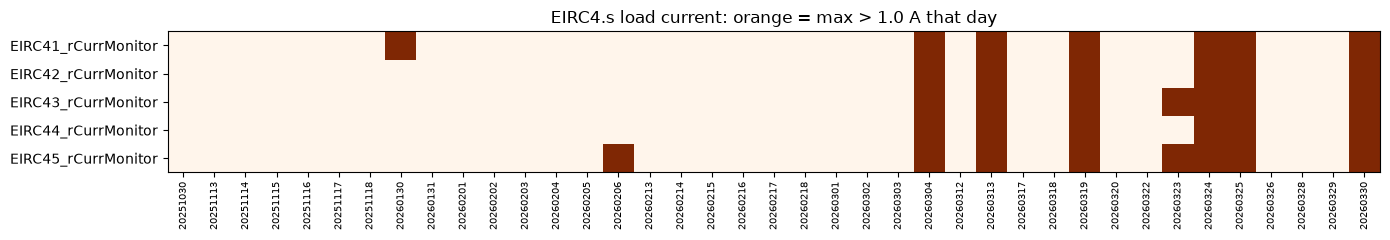

days with any string loaded: 20260130, 20260206, 20260304, 20260313, 20260319, 20260323, 20260324, 20260325, 20260330


day,20251030,20251113,20251114,20251115,20251116,20251117,20251118,20260130,20260131,20260201,...,20260319,20260320,20260322,20260323,20260324,20260325,20260326,20260328,20260329,20260330
col,,,,,,,,,,,,,,,,,,,,,
EIRC41_rCurrMonitor,0.84,0.00,0.0,0.0,0.0,0.0,0.00,3.59,0.0,0.0,...,14.64,0.0,0.00,0.0,14.99,18.01,0.01,0.00,0.0,3.81
EIRC42_rCurrMonitor,0.00,0.00,0.0,0.0,0.0,0.0,0.00,0.00,0.0,0.0,...,10.68,0.0,0.00,0.0,15.00,17.99,0.00,0.00,0.0,3.82
EIRC43_rCurrMonitor,0.00,0.01,0.0,0.0,0.0,0.0,0.01,0.00,0.0,0.0,...,13.73,0.0,0.01,3.0,15.01,18.01,0.01,0.01,0.0,3.82
EIRC44_rCurrMonitor,0.00,0.00,0.0,0.0,0.0,0.0,0.00,0.00,0.0,0.0,...,10.10,0.0,0.00,0.0,15.00,9.96,0.00,0.00,0.0,3.79
EIRC45_rCurrMonitor,0.00,0.00,0.0,0.0,0.0,0.0,0.00,0.00,0.0,0.0,...,13.95,0.0,0.00,2.4,14.09,18.10,0.00,0.00,0.0,3.81


In [14]:
eirc_i = [c for c in TARGET_COLS if c.endswith("_rCurrMonitor")]
loaded = (stats[stats["col"].isin(eirc_i)]
          .assign(loaded=lambda d: d["max"] > LOAD_ON_A)
          .pivot(index="col", columns="day", values="loaded"))

fig, ax = plt.subplots(figsize=(14, 2.5))
ax.imshow(loaded.astype(float).values, aspect="auto", cmap="Oranges", vmin=0, vmax=1)
ax.set_yticks(range(len(loaded)), [c.replace("PLC_hostSetp_ctrl_ct", "") for c in loaded.index])
ax.set_xticks(range(loaded.shape[1]), loaded.columns, rotation=90, fontsize=7)
ax.set_title(f"EIRC4.s load current: orange = max > {LOAD_ON_A} A that day")
plt.tight_layout()
plt.show()
print("days with any string loaded:", ", ".join(loaded.columns[loaded.any()]))
(stats[stats["col"].isin(eirc_i)].pivot(index="day", columns="col", values="max")
 .rename(columns=lambda c: c.replace("PLC_hostSetp_ctrl_ct", "")).round(2).T)

## 5. Column selection

Kept: the stage columns with status **varying**. This drops the stuck stack thermocouple `TIR_4_6_19` (reads only `-1` / 1300).
`TIR_4_6_25` is varying but reads ambient whatever the stack does; it is kept here and dropped by `operating_states.load_signals`,
which removes thermocouples that sit far from the module median.

Edit `EXTRA_KEEP` / `EXTRA_DROP` to change the selection by hand.

In [15]:
EXTRA_KEEP = []
EXTRA_DROP = []

status = summary.set_index("col")["status"]
keep = [c for c in TARGET_COLS if (status[c] == "varying" or c in EXTRA_KEEP) and c not in EXTRA_DROP]   # file order

dropped = summary.loc[~summary["col"].isin(keep), ["col", "family", "status"]]
print(f"keeping {len(keep)} of {len(TARGET_COLS)} stage columns, dropping {len(dropped)}")
display(dropped)
pd.Series([family(c) for c in keep]).value_counts()

keeping 52 of 53 stage columns, dropping 1


,col,family,status
27,TIR_4_6_19,TIR,sentinel + one value


TIR     39
EIRC    11
TIRC     1
PIR      1
Name: count, dtype: int64

## 6. Clean and export

For each day:
* read only the kept columns
* turn `SENTINEL` (-1) into NaN
* add `EIRC_4s_Power_kW` = `rVoltMonitor` × `rCurrMonitor` / 1000 per string (at 1 Hz, before resampling)
* resample to `RESAMPLE` means (a window with no valid readings stays NaN)
* write `../02_data/preprocessed/<day>.parquet`

Run one day first to check the output.

In [16]:
def add_string_power(df):
    """EIRC4.s string power [kW] = load voltage x load current / 1000."""
    for s in range(1, 6):
        v, i = f"PLC_hostSetp_ctrl_ctEIRC4{s}_rVoltMonitor", f"PLC_hostSetp_ctrl_ctEIRC4{s}_rCurrMonitor"
        if v in df and i in df:
            df[f"EIRC_4{s}_Power_kW"] = df[v] * df[i] / 1000
    return df


def clean_day(path, columns=keep, resample=RESAMPLE):
    df = load_day(path, columns)
    df = df.mask(df == SENTINEL)
    df = add_string_power(df)
    if resample:
        df = df.resample(resample).mean()
    return df


sample = clean_day(files[-1])
print(sample.shape)
sample.describe().T.head(15)

(8640, 57)


,count,mean,std,min,25%,50%,75%,max
TIR_1_1_1,8633.0,16.907371,2.013492,11.69,15.99,17.28,18.00,20.31
TIR_1_2_1,8633.0,13.180755,2.281513,10.78,11.30,12.40,14.90,17.79
TIR_1_3,8633.0,3.807949,2.865746,0.76,1.85,2.80,4.79,13.61
TIR_1_4_1,8633.0,12.651363,2.024644,8.64,10.90,12.19,13.90,17.30
TIR_4_6_10,8633.0,506.209223,139.263551,257.96,371.90,590.78,591.35,698.89
TIR_4_6_11,8633.0,507.546253,141.191061,258.29,371.13,592.90,593.39,720.12
TIR_4_6_12,8633.0,499.150884,138.831502,250.63,359.00,588.90,589.60,653.80
TIR_4_6_13,8633.0,501.090781,141.792738,247.58,357.31,591.50,592.10,669.07
TIR_4_6_14,8633.0,502.615427,141.566594,250.90,359.44,591.30,592.17,679.70
TIR_4_6_15,8633.0,504.466557,141.368663,253.10,363.80,591.88,592.60,689.45


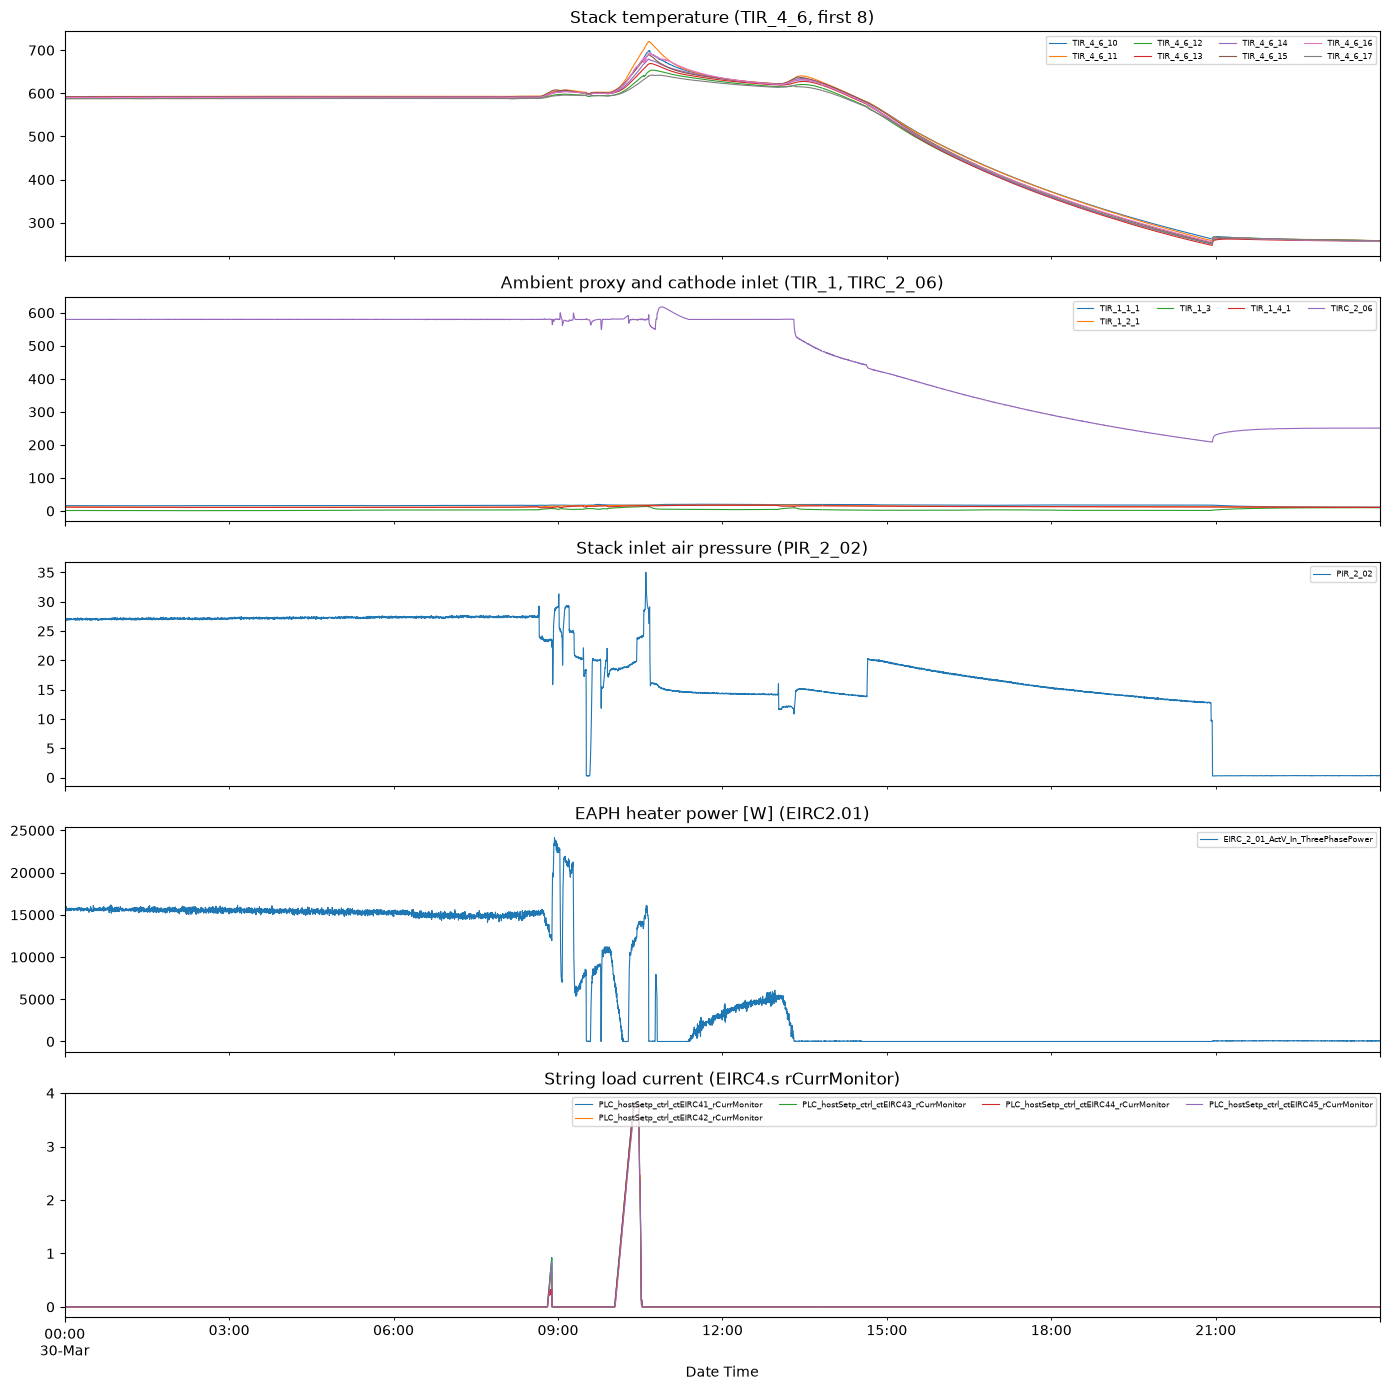

In [17]:
fig, axes = plt.subplots(5, 1, figsize=(14, 14), sharex=True)
groups = [
    ("Stack temperature (TIR_4_6, first 8)", [c for c in keep if c.startswith("TIR_4_6_")][:8]),
    ("Ambient proxy and cathode inlet (TIR_1, TIRC_2_06)", [c for c in keep if c in ops.AMB_COLS or c == "TIRC_2_06"]),
    ("Stack inlet air pressure (PIR_2_02)", [c for c in keep if c == "PIR_2_02"]),
    ("EAPH heater power [W] (EIRC2.01)", [c for c in keep if c.startswith("EIRC_2_01")]),
    ("String load current (EIRC4.s rCurrMonitor)", [c for c in sample.columns if c.endswith("_rCurrMonitor")]),
]
for ax, (title, cs) in zip(axes, groups):
    sample[cs].plot(ax=ax, lw=0.8, legend=False)
    ax.set_title(title)
    ax.legend(cs, fontsize=6, ncol=4, loc="upper right")
plt.tight_layout()
plt.show()

In [18]:
import pyarrow.parquet as pq

EXPORT_COLS = set(sample.columns)   # kept columns + derived string power


def export_day(path):
    out = OUT / f"{path.stem}.parquet"
    if out.exists() and EXPORT_COLS <= set(pq.read_schema(out).names):
        return path.stem, "skipped (exists)"
    df = clean_day(path)
    df.to_parquet(out)
    return path.stem, f"{len(df):,} rows"


OUT.mkdir(parents=True, exist_ok=True)
t0 = time.time()
with ThreadPoolExecutor(N_THREADS) as ex:
    for day, msg in ex.map(export_day, files):
        print(day, msg)
print(f"done in {time.time() - t0:.0f}s")

20251030 8,640 rows
20251113 8,640 rows
20251114 8,640 rows
20251115 8,640 rows
20251116 8,640 rows
20251117 8,640 rows
20251118 8,640 rows
20260130 8,640 rows


20260131 8,640 rows


20260201 8,640 rows
20260202 8,640 rows
20260203 8,640 rows
20260204 8,640 rows
20260205 8,640 rows
20260206 8,640 rows
20260213 8,640 rows


20260214 8,640 rows


20260215 8,640 rows
20260216 8,640 rows
20260217 8,640 rows
20260218 8,640 rows
20260301 8,640 rows


20260302 8,640 rows
20260303 8,640 rows


20260304 8,640 rows
20260312 8,640 rows


20260313 8,640 rows
20260317 8,640 rows
20260318 8,640 rows
20260319 8,640 rows
20260320 8,640 rows
20260322 8,301 rows
20260323 5,515 rows


20260324 8,640 rows


20260325 8,640 rows
20260326 8,640 rows
20260328 8,640 rows
20260329 8,640 rows
20260330 8,640 rows
done in 37s


In [19]:
# Load the full cleaned dataset back and save the column report
data = pd.concat([pd.read_parquet(p) for p in sorted(OUT.glob("*.parquet"))]).sort_index()
print(data.shape, data.index.min(), "->", data.index.max())

summary.assign(kept=summary["col"].isin(keep)).to_csv(REPORT / "column_report.csv", index=False)
data.isna().mean().sort_values(ascending=False).head(15).rename("NaN fraction")

(333496, 57) 2025-10-30 00:00:00 -> 2026-03-30 23:59:50


TIR_1_3       0.016855
TIR_1_1_1     0.012243
TIR_1_2_1     0.012243
TIR_1_4_1     0.012243
TIR_4_6_10    0.012243
TIR_4_6_11    0.012243
TIR_4_6_12    0.012243
TIR_4_6_13    0.012243
TIR_4_6_14    0.012243
TIR_4_6_15    0.012243
TIR_4_6_16    0.012243
TIR_4_6_17    0.012243
TIR_4_6_18    0.012243
TIR_4_6_1     0.012243
TIR_4_6_20    0.012243
Name: NaN fraction, dtype: float64

## 7. Column groups for visualization (single day file)

Columns are grouped by family and section number, the first number after the prefix:
`TIR_1_1_1, ...` → **TIR_1** (ambient proxy), `TIR_4_6_1, ...` → **TIR_4** (stack thermocouples), `TIRC_2_06` → **TIRC_2**, `PIR_2_02` → **PIR_2**.
EIRC columns are grouped by device and quantity so volts, amps and watts never share an axis:
**EIRC_2_P** (EAPH controller 3-phase power) and **EIRC_4_V / _I / _P** (the 5 string loads: voltage, current, power).

`groups` maps each group name to its columns and is saved to `preprocessing/stage/column_groups.json`.

In [20]:
import json

GROUP_RE = re.compile(r"^(TIRZ|TIRC|TIR|PIRZ|PIR)_(\d+)")


EIRC_GROUPS = [   # (column suffix, group)
    ("_MainsVoltage", "EIRC_2_V"), ("_Current", "EIRC_2_I"), ("_MainsFreq", "EIRC_2_F"),
    ("_ThreePhasePower", "EIRC_2_P"),
    ("_rVoltMonitor", "EIRC_4_V"), ("_rCurrMonitor", "EIRC_4_I"), ("_Power_kW", "EIRC_4_P"),
    ("_rVoltCellMin_ActV", "EIRC_4_Vcell"),
]
FAMILY_ORDER = ["TIR", "TIRC", "TIRZ", "PIR", "PIRZ", "FIRC", "EIRC"]


def group_of(col):
    if "FIRC" in col:
        return "FIRC"
    if "EIRC" in col:
        return next((g for suffix, g in EIRC_GROUPS if col.endswith(suffix)), "EIRC_9")
    m = GROUP_RE.match(col)
    return f"{m.group(1)}_{m.group(2)}"


def group_sort_key(g):
    fam, _, rest = g.partition("_")
    num, _, quantity = rest.partition("_")
    order = [q for _, q in EIRC_GROUPS]
    return (FAMILY_ORDER.index(fam), int(num or 0), order.index(g) if g in order else 0)


groups = {}
for c in sample.columns:   # kept columns + derived string power
    groups.setdefault(group_of(c), []).append(c)
groups = dict(sorted(groups.items(), key=lambda kv: group_sort_key(kv[0])))
FAMILIES = [f for f in FAMILY_ORDER if any(g.split("_")[0] == f for g in groups)]   # families with stage columns

with open(REPORT / "column_groups.json", "w") as fh:
    json.dump(groups, fh, indent=2)

pd.DataFrame({"columns": {g: len(cs) for g, cs in groups.items()},
              "example": {g: ", ".join(cs[:3]) + (" ..." if len(cs) > 3 else "") for g, cs in groups.items()}})

,columns,example
TIR_1,4,"TIR_1_1_1, TIR_1_2_1, TIR_1_3 ..."
TIR_4,35,"TIR_4_6_10, TIR_4_6_11, TIR_4_6_12 ..."
TIRC_2,1,TIRC_2_06
PIR_2,1,PIR_2_02
EIRC_2_P,1,EIRC_2_01_ActV_In_ThreePhasePower
EIRC_4_V,5,"PLC_hostSetp_ctrl_ctEIRC41_rVoltMonitor, PLC_h..."
EIRC_4_I,5,"PLC_hostSetp_ctrl_ctEIRC41_rCurrMonitor, PLC_h..."
EIRC_4_P,5,"EIRC_41_Power_kW, EIRC_42_Power_kW, EIRC_43_Po..."


### Pick one day file

All plots below use **one file only**, set by `DAY`. It is read from the raw `.txt` at full 1 s resolution, with `-1` turned into NaN.
Change `DAY` and rerun this section to look at another day (available days are printed below).

In [21]:
DAY = "20260330"   # yyyymmdd, one of the files in ../02_data/common

print("available days:", ", ".join(f.stem for f in files))
day_df = clean_day(SRC / f"{DAY}.txt", resample=None)
print(f"{fmt_day(DAY)}: {day_df.shape[0]:,} rows x {day_df.shape[1]} columns, "
      f"{day_df.index.min()} -> {day_df.index.max()}")

# Per-group overview for this day: how many columns actually change
pd.DataFrame({
    g: {"columns": len(cs),
        "varying this day": int((day_df[cs].nunique() > 1).sum()),
        "min": day_df[cs].min().min(),
        "max": day_df[cs].max().max()}
    for g, cs in groups.items()
}).T

available days: 20251030, 20251113, 20251114, 20251115, 20251116, 20251117, 20251118, 20260130, 20260131, 20260201, 20260202, 20260203, 20260204, 20260205, 20260206, 20260213, 20260214, 20260215, 20260216, 20260217, 20260218, 20260301, 20260302, 20260303, 20260304, 20260312, 20260313, 20260317, 20260318, 20260319, 20260320, 20260322, 20260323, 20260324, 20260325, 20260326, 20260328, 20260329, 20260330


30 Mar 2026: 86,158 rows x 57 columns, 2026-03-30 00:00:00 -> 2026-03-30 23:59:59


,columns,varying this day,min,max
TIR_1,4.0,4.0,0.7000,20.400000
TIR_4,35.0,35.0,29.3000,720.200000
TIRC_2,1.0,1.0,208.3000,617.900000
PIR_2,1.0,1.0,0.1465,35.926400
EIRC_2_P,1.0,1.0,0.0000,24874.433600
EIRC_4_V,5.0,5.0,0.0000,522.942300
EIRC_4_I,5.0,5.0,0.0000,3.822000
EIRC_4_P,5.0,5.0,0.0000,1.895706


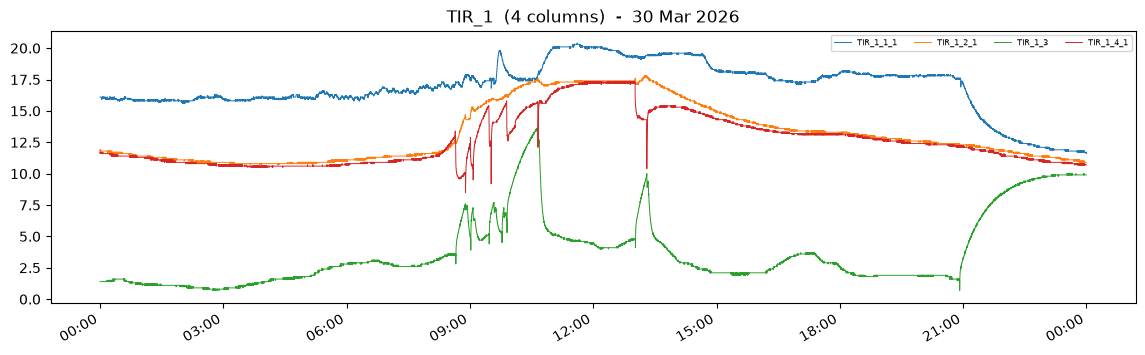

In [22]:
def plot_group(name, df=None, rule=None, ax=None, legend_max=12, label=None):
    '''Plot all columns of one group for the selected day (rule e.g. "1min" to smooth).'''
    df = day_df if df is None else df
    d = df[groups[name]]
    if rule:
        d = d.resample(rule).mean()
    if ax is None:
        _, ax = plt.subplots(figsize=(14, 4))
    d.plot(ax=ax, lw=0.7, legend=False, x_compat=True)
    one_day = d.index.max() - d.index.min() <= pd.Timedelta(days=1)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M" if one_day else "%d %b %Y"))
    ax.set_title(f"{name}  ({len(groups[name])} columns)  -  {label or fmt_day(DAY)}")
    ax.set_xlabel("")
    if len(groups[name]) <= legend_max:
        ax.legend(fontsize=6, ncol=min(4, len(groups[name])), loc="upper right")
    return ax


def plot_family(prefix, df=None, rule=None, label=None):
    '''One subplot per group for the selected day, e.g. plot_family("TIR") -> TIR_1 ... TIR_7.'''
    names = [g for g in groups if g.split("_")[0] == prefix]
    if not names:
        return
    fig, axes = plt.subplots(len(names), 1, figsize=(14, 2.8 * len(names)), sharex=True, squeeze=False)
    for ax, name in zip(axes[:, 0], names):
        plot_group(name, df, rule, ax=ax, label=label)
    plt.tight_layout()
    plt.show()


plot_group("TIR_1");

### Temperature groups (TIR: ambient proxy TIR_1, stack thermocouples TIR_4)

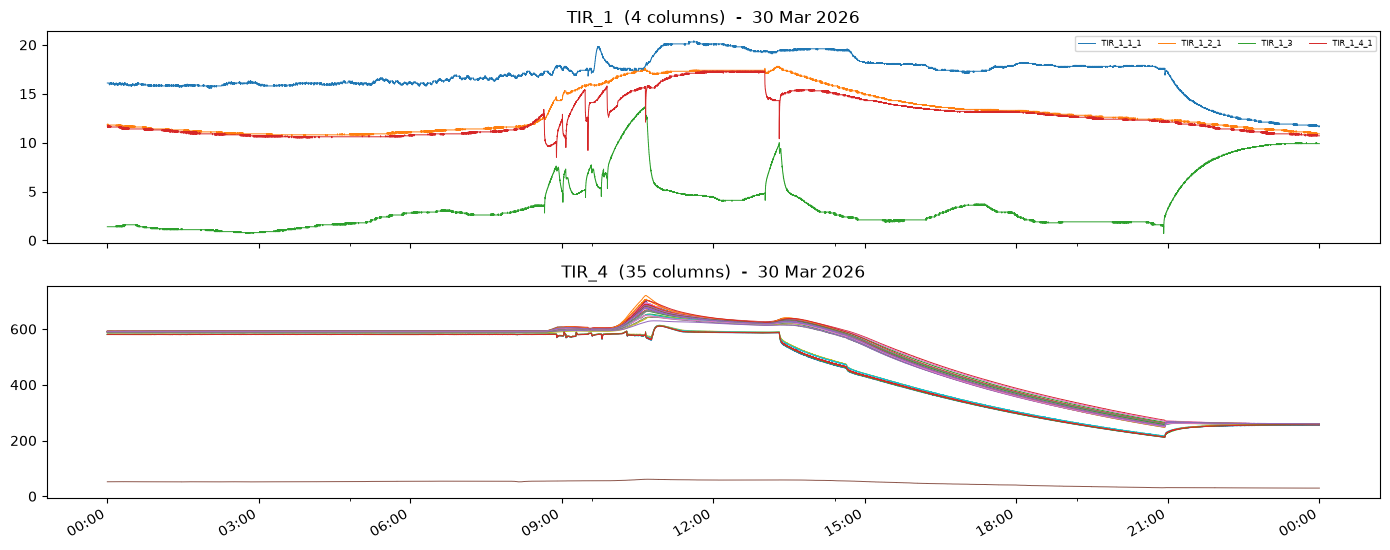

In [23]:
plot_family("TIR")

### Cathode inlet temperature (TIRC_2_06)

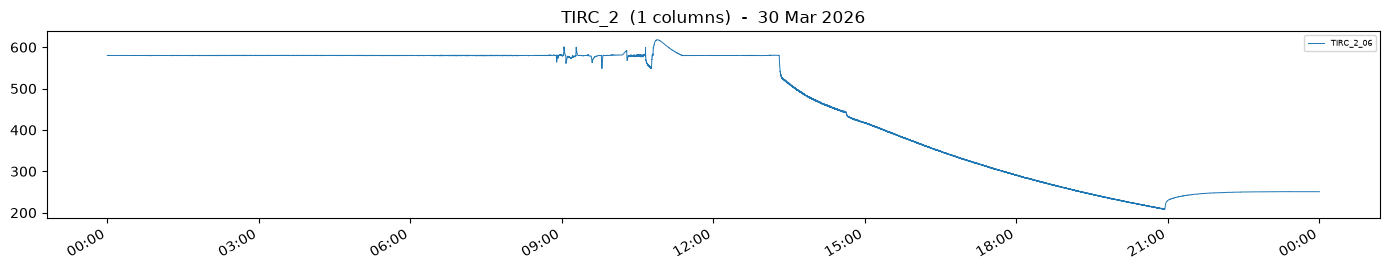

In [24]:
plot_family("TIRC")

### Stack inlet air pressure (PIR_2_02)

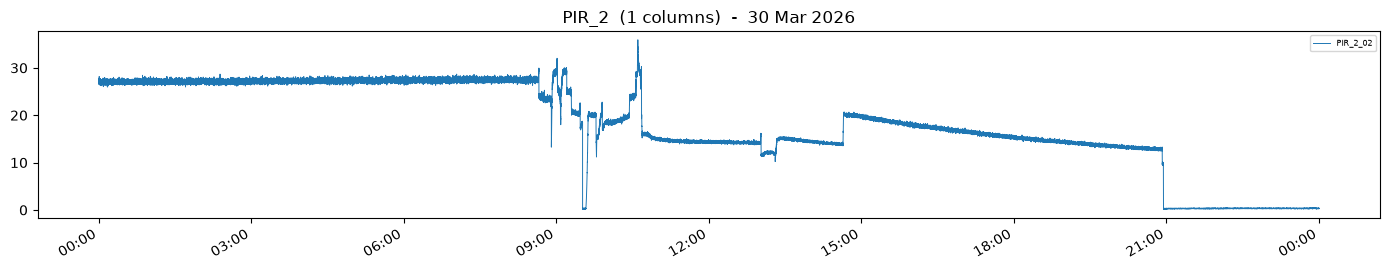

In [25]:
plot_family("PIR")

### Electrical (EIRC)

EAPH heater power (EIRC2.01) and the 5 string loads (EIRC4.1 … 4.5). The string loads only show real values while the load is on; see the load heatmap in section 3.

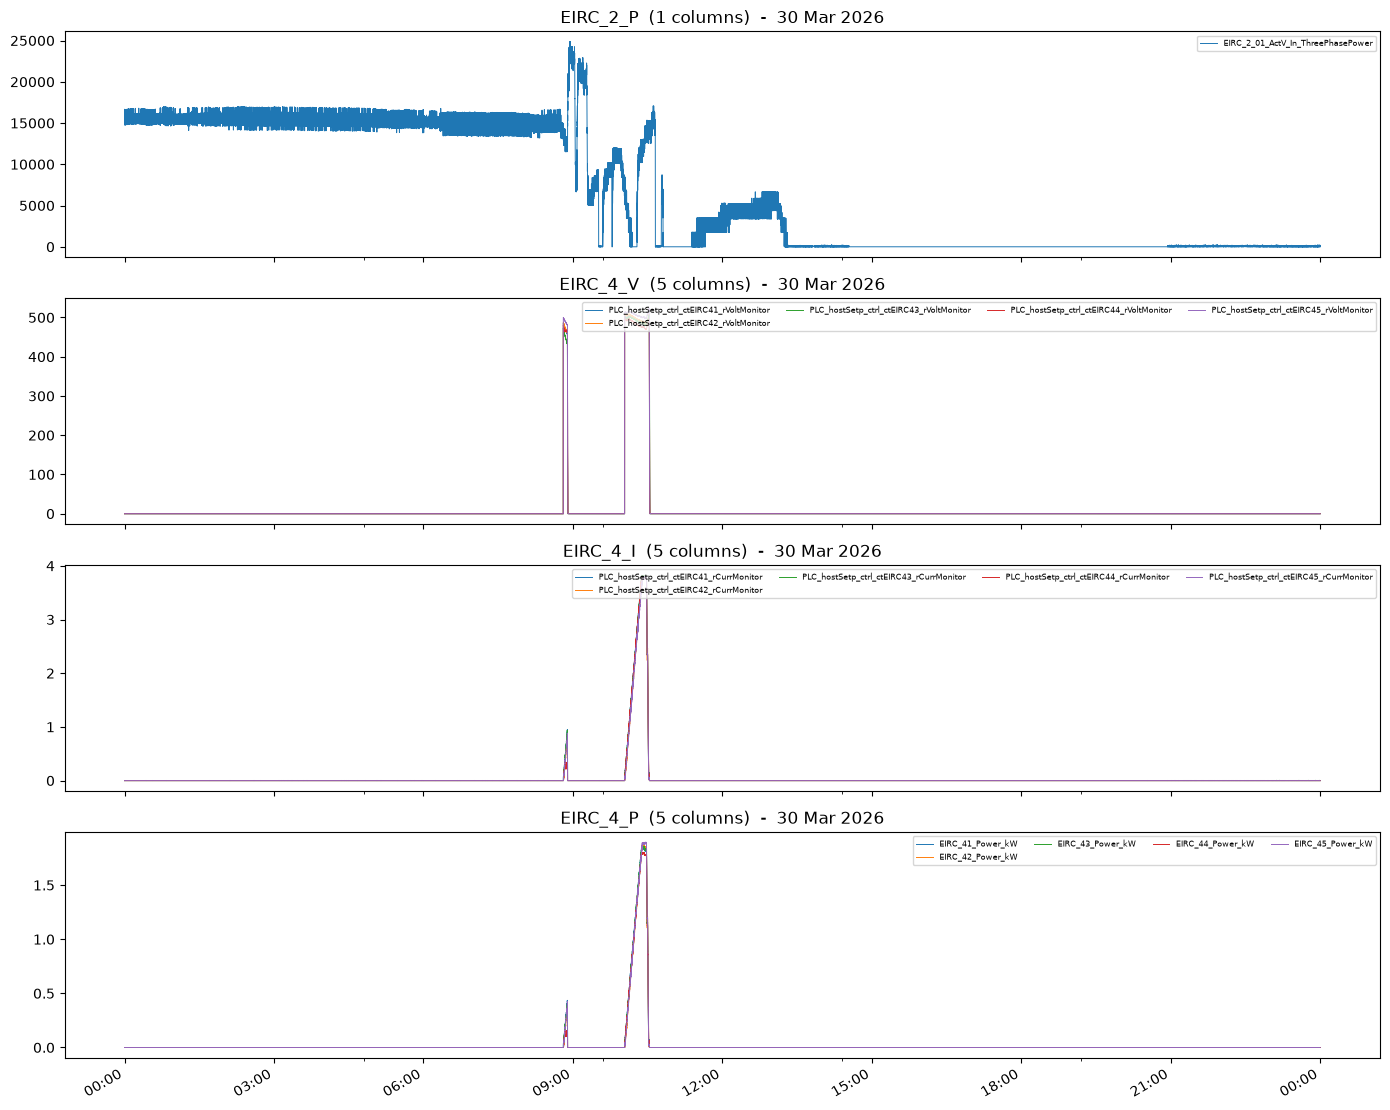

In [26]:
plot_family("EIRC")

### Zoom into a time window of the day

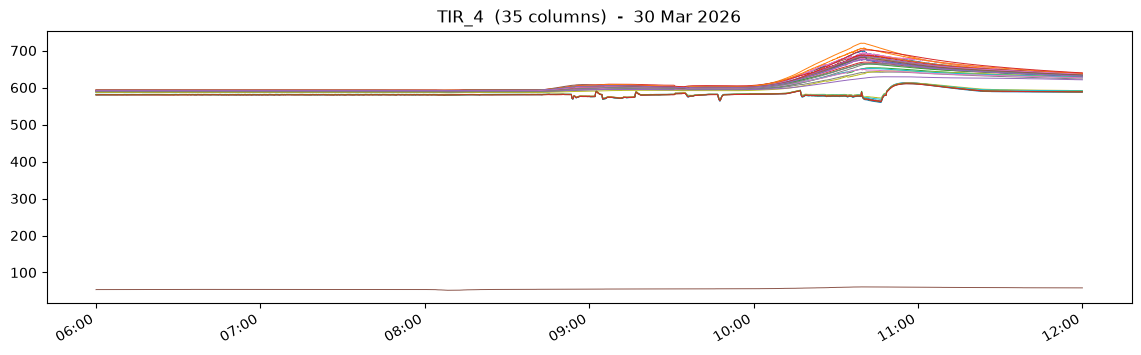

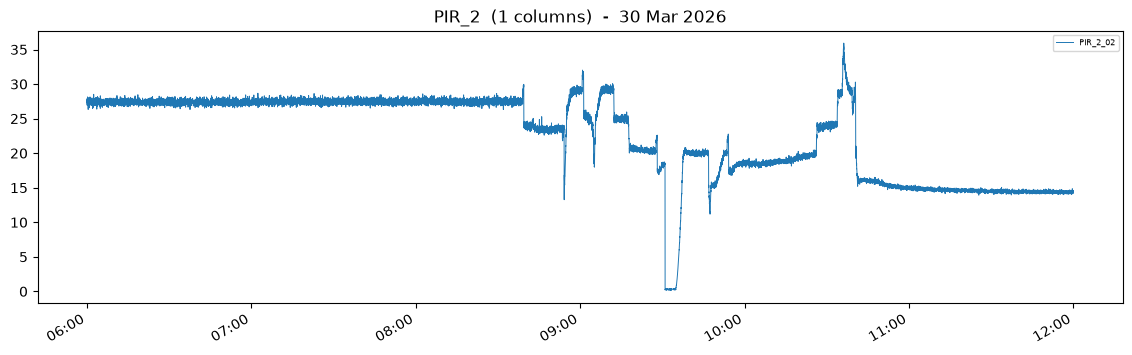

In [27]:
plot_group("TIR_4", day_df.between_time("06:00", "12:00"))
plot_group("PIR_2", day_df.between_time("06:00", "12:00"));

## 8. Continuous day runs

The day files are not one unbroken series: recording happened in blocks of back-to-back days with long breaks in between.
Each **run of consecutive day files** gets its own set of group plots, so nothing is drawn across a gap.

Runs are read from the cleaned 10 s parquet files in `../02_data/preprocessed_stage/` (section 6) and resampled to `RUN_RULE` for plotting.
A partial day inside a run (e.g. 20260323) shows up as a gap in the lines.

In [28]:
RUN_RULE = "1min"   # resample rule for multi-day plots

day_dates = pd.to_datetime([f.stem for f in files], format="%Y%m%d")
run_id = (pd.Series(day_dates).diff() != pd.Timedelta(days=1)).cumsum() - 1
runs = (pd.DataFrame({"day": [f.stem for f in files], "run": run_id.values})
        .groupby("run")["day"].agg(start="first", end="last", days="count"))
runs

,start,end,days
run,,,
0,20251030,20251030,1
1,20251113,20251118,6
2,20260130,20260206,8
3,20260213,20260218,6
4,20260301,20260304,4
5,20260312,20260313,2
6,20260317,20260320,4
7,20260322,20260326,5
8,20260328,20260330,3


In [29]:
def load_run(run, rule=RUN_RULE):
    days = runs.loc[run]
    df = pd.concat([pd.read_parquet(OUT / f"{d.strftime('%Y%m%d')}.parquet")
                    for d in pd.date_range(days["start"], days["end"])])
    return df.resample(rule).mean() if rule else df


def run_label(run):
    r = runs.loc[run]
    if r["days"] == 1:
        return fmt_day(r["start"])
    return f"{fmt_day(r['start'])} - {fmt_day(r['end'])} ({r['days']} days)"


def plot_run(run, families=FAMILIES):
    df = load_run(run)
    for prefix in families:
        plot_family(prefix, df, label=run_label(run))

### 30 Oct 2025

30 Oct 2025


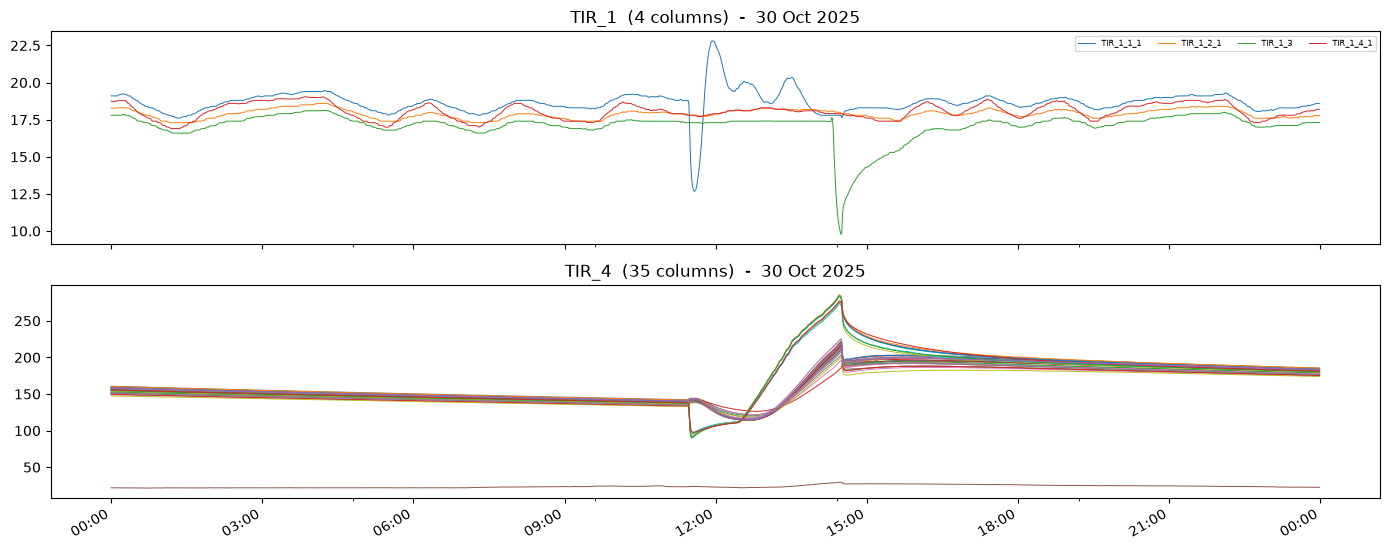

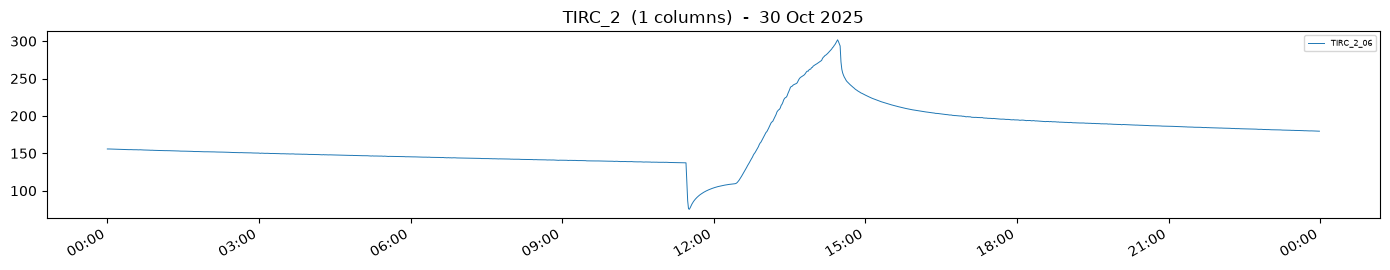

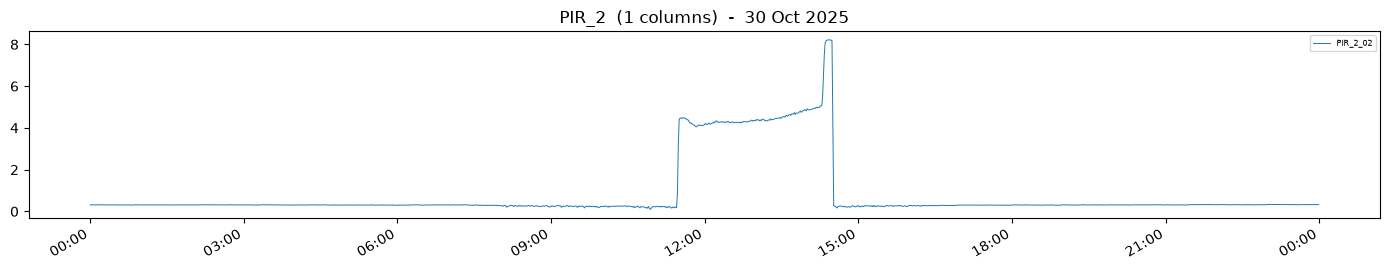

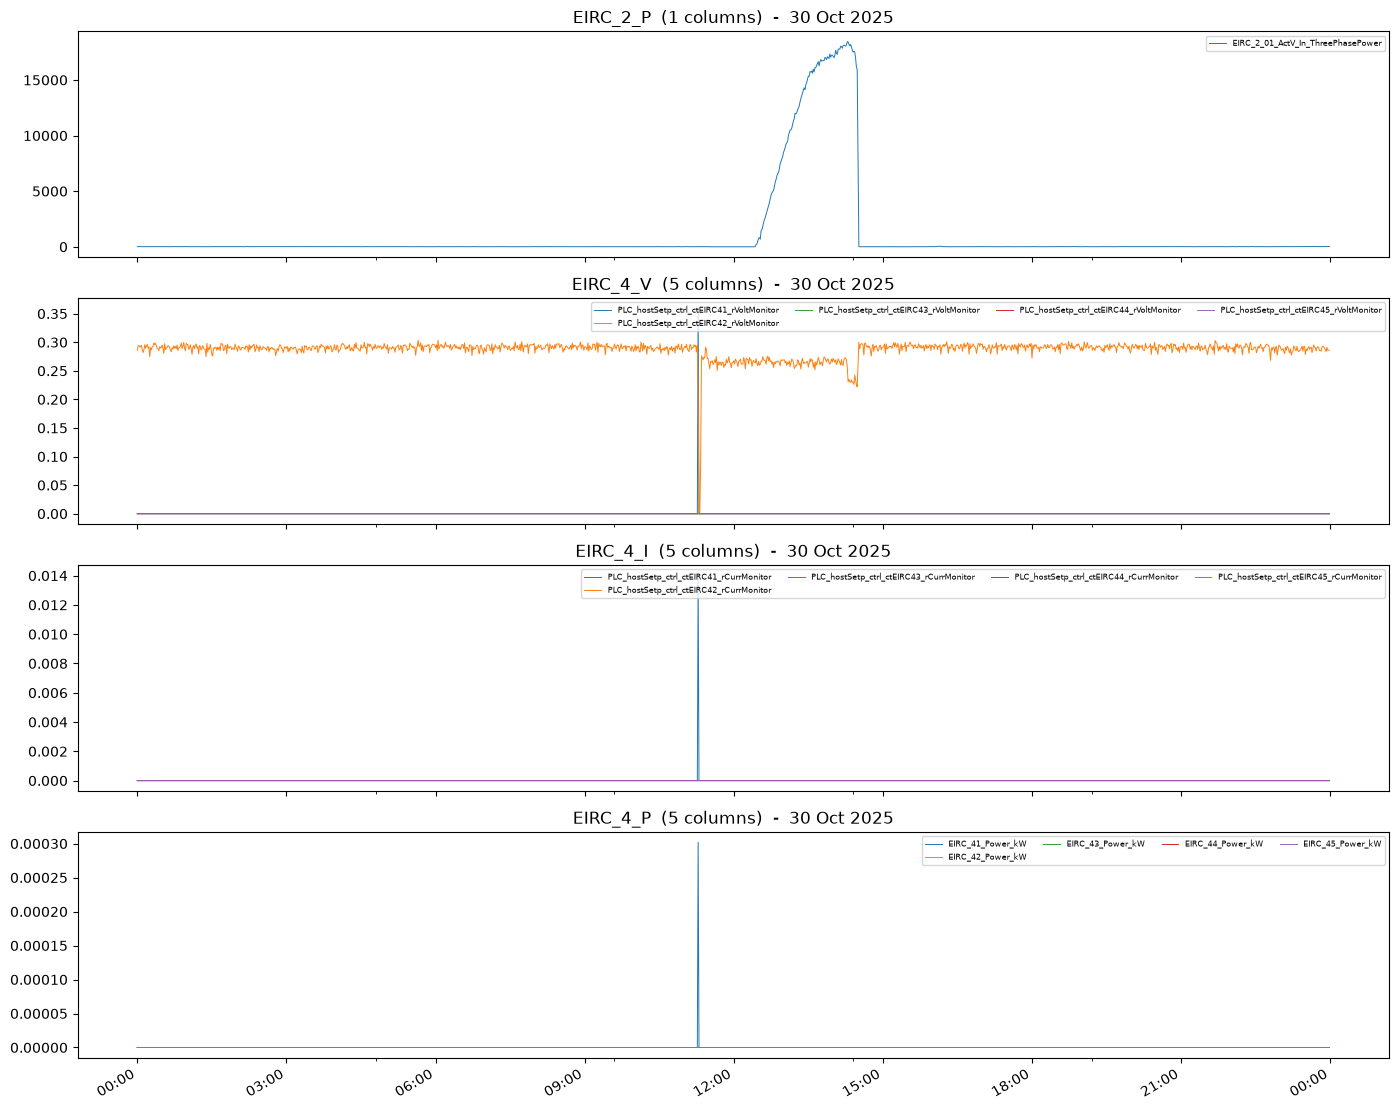

In [30]:
print(run_label(0))
plot_run(0)

### 13 Nov 2025 - 18 Nov 2025

13 Nov 2025 - 18 Nov 2025 (6 days)


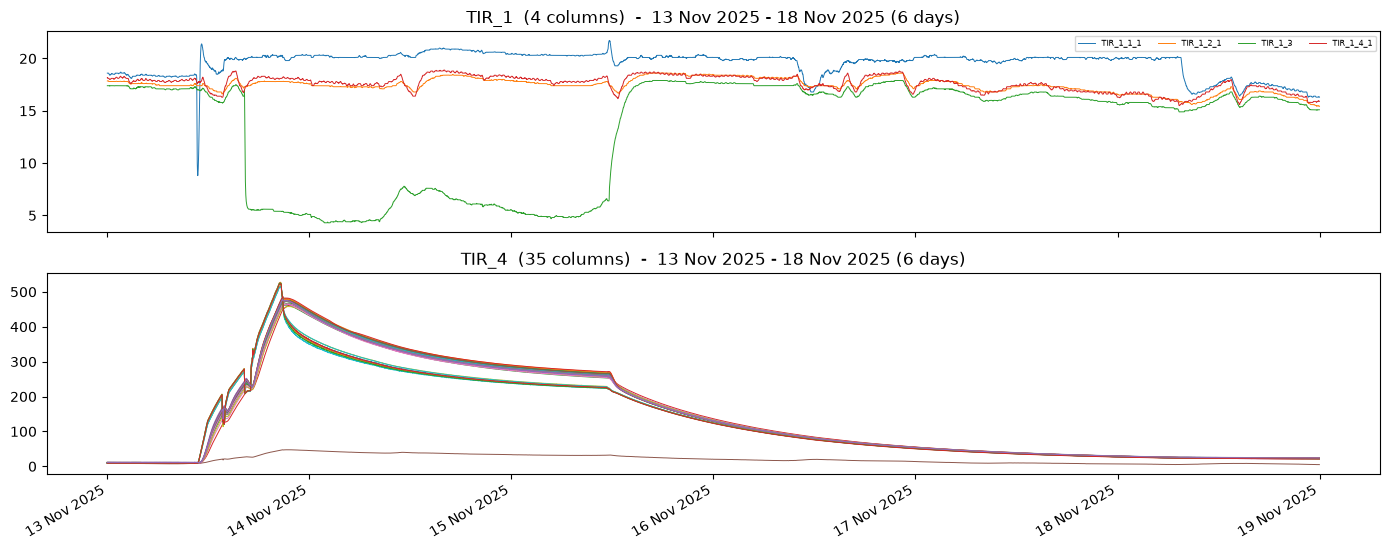

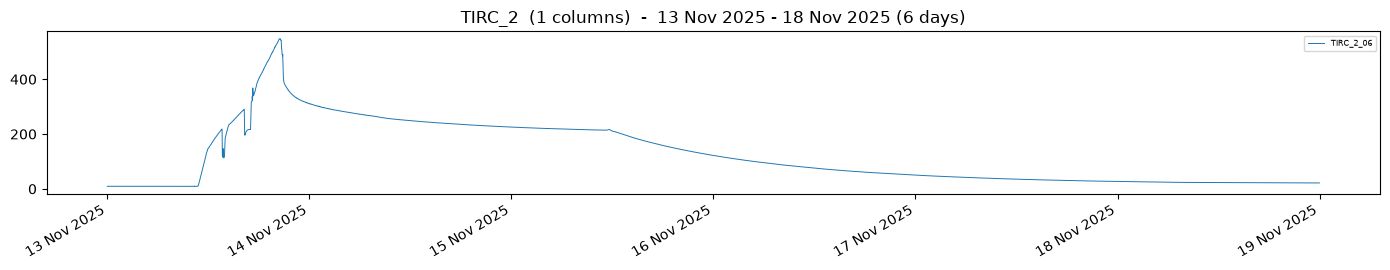

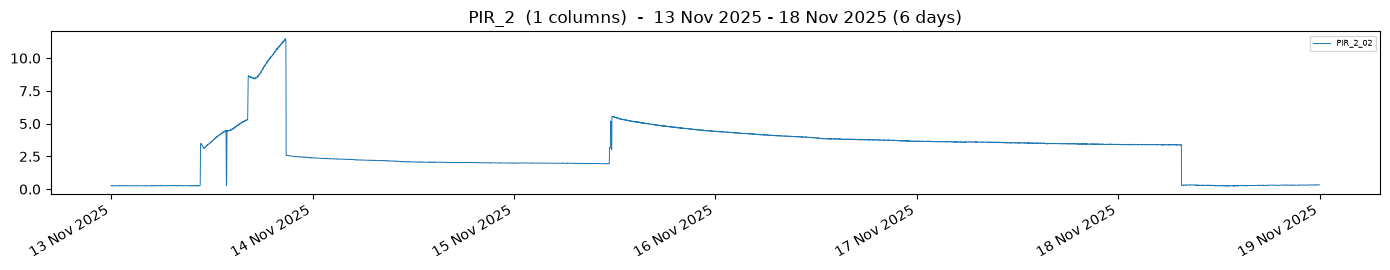

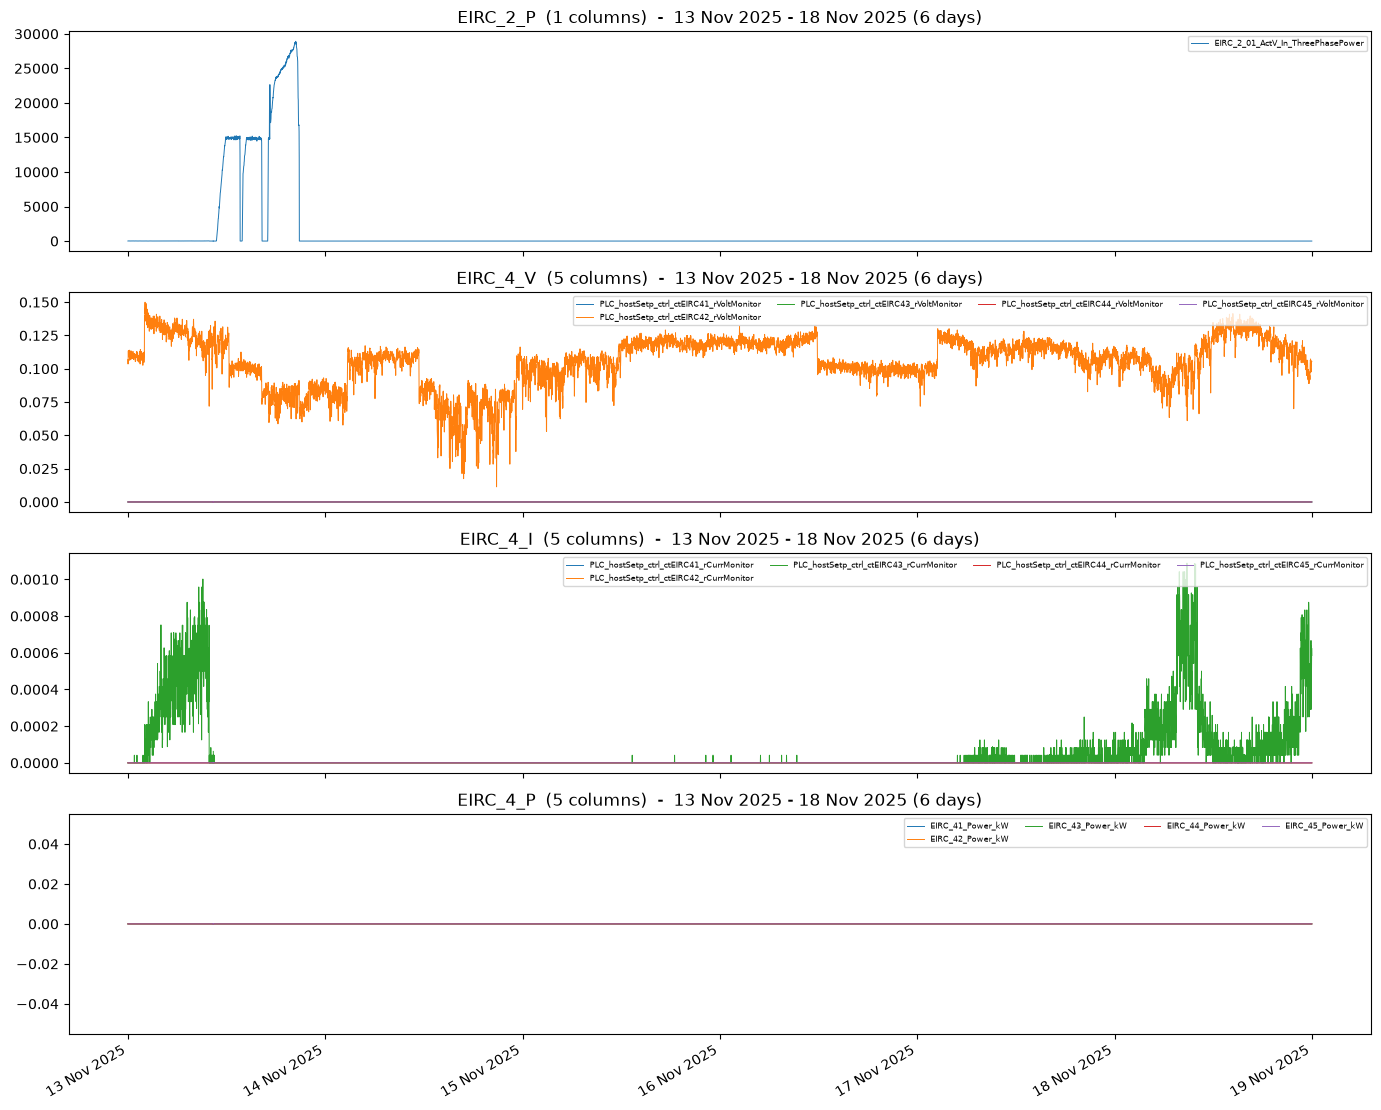

In [31]:
print(run_label(1))
plot_run(1)

### 30 Jan 2026 - 06 Feb 2026

30 Jan 2026 - 06 Feb 2026 (8 days)


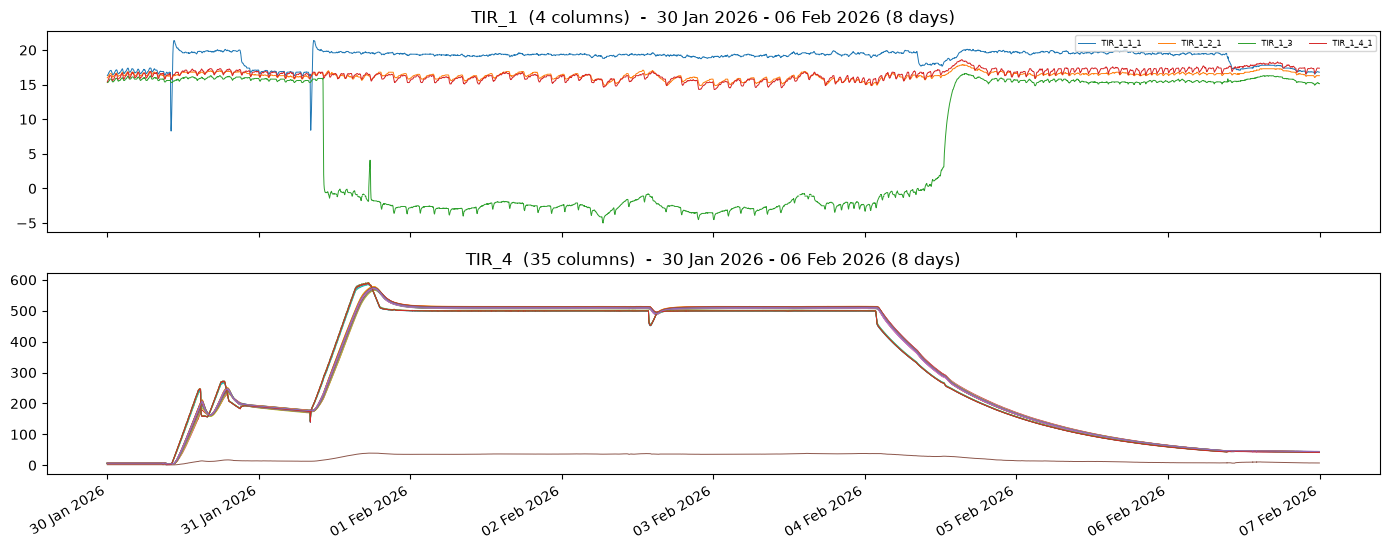

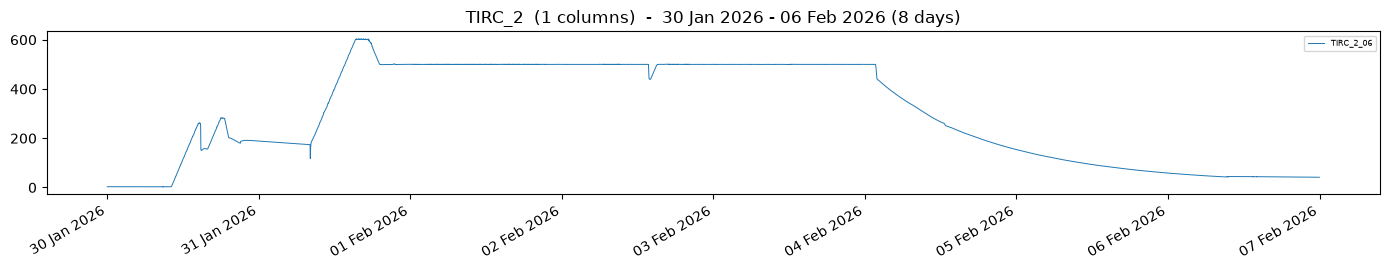

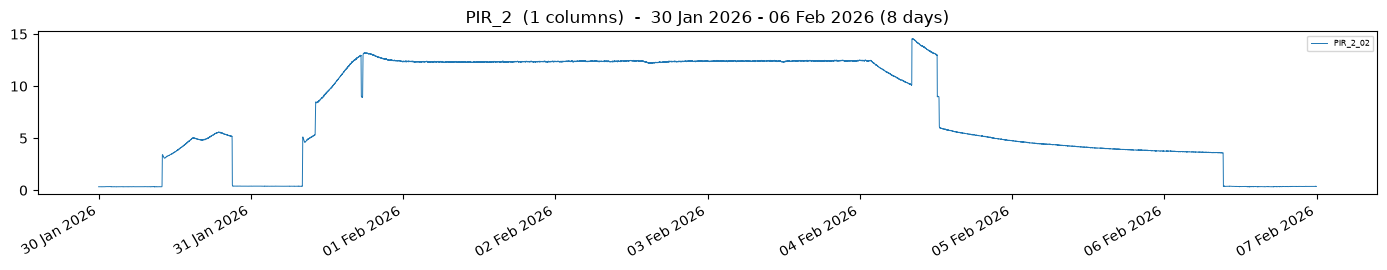

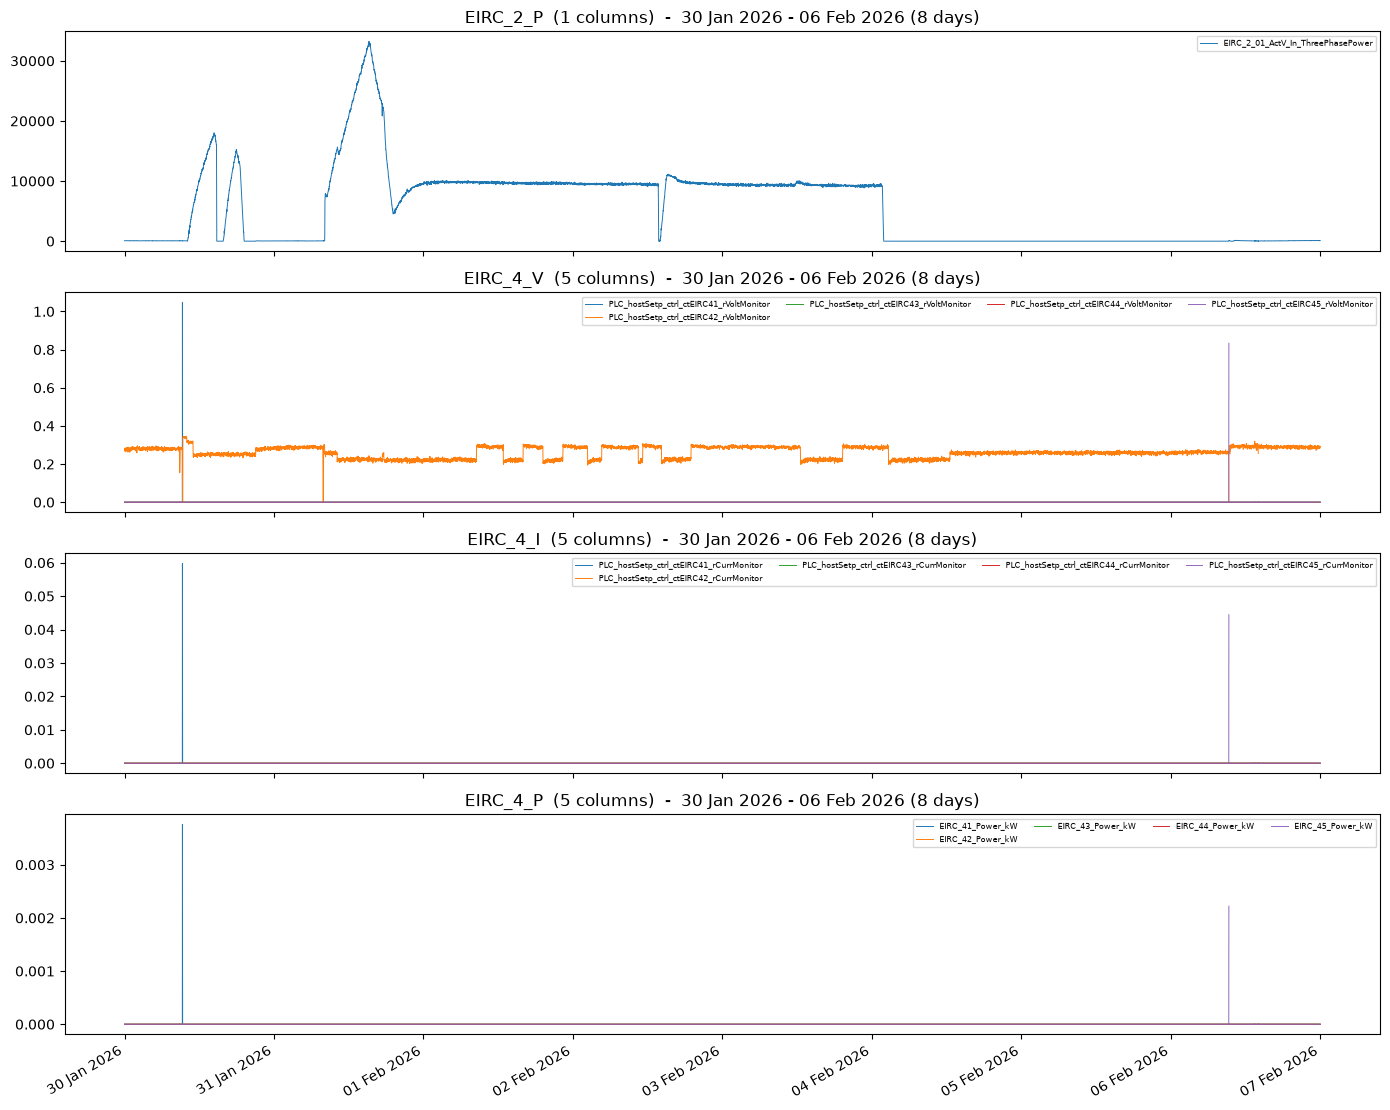

In [32]:
print(run_label(2))
plot_run(2)

### 13 Feb 2026 - 18 Feb 2026

13 Feb 2026 - 18 Feb 2026 (6 days)


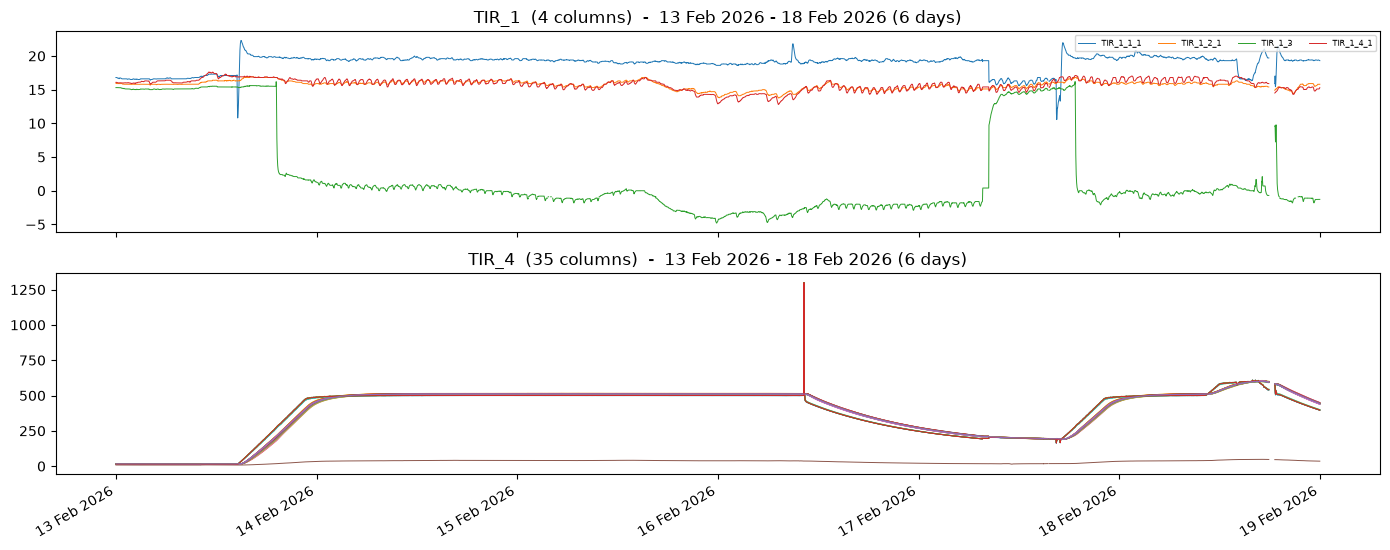

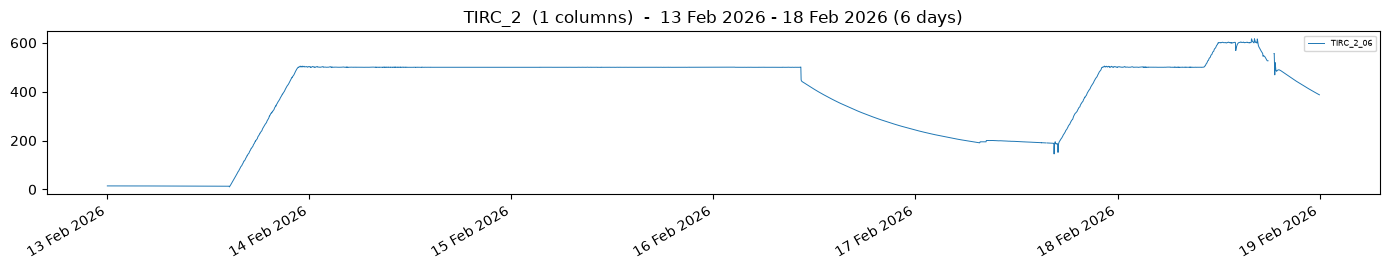

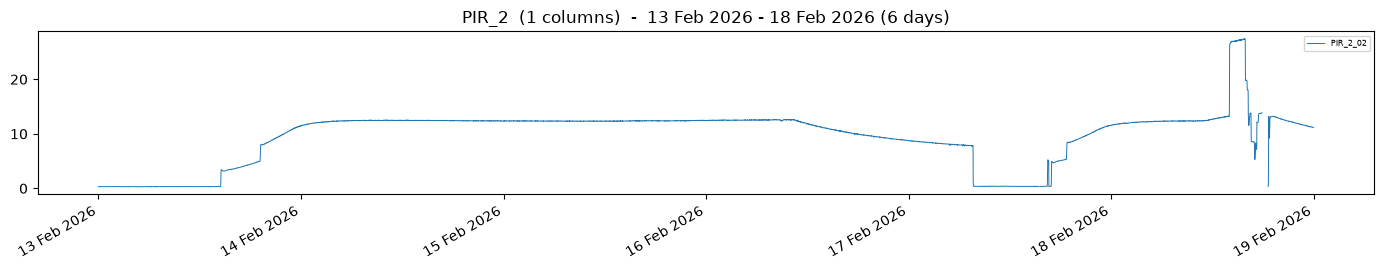

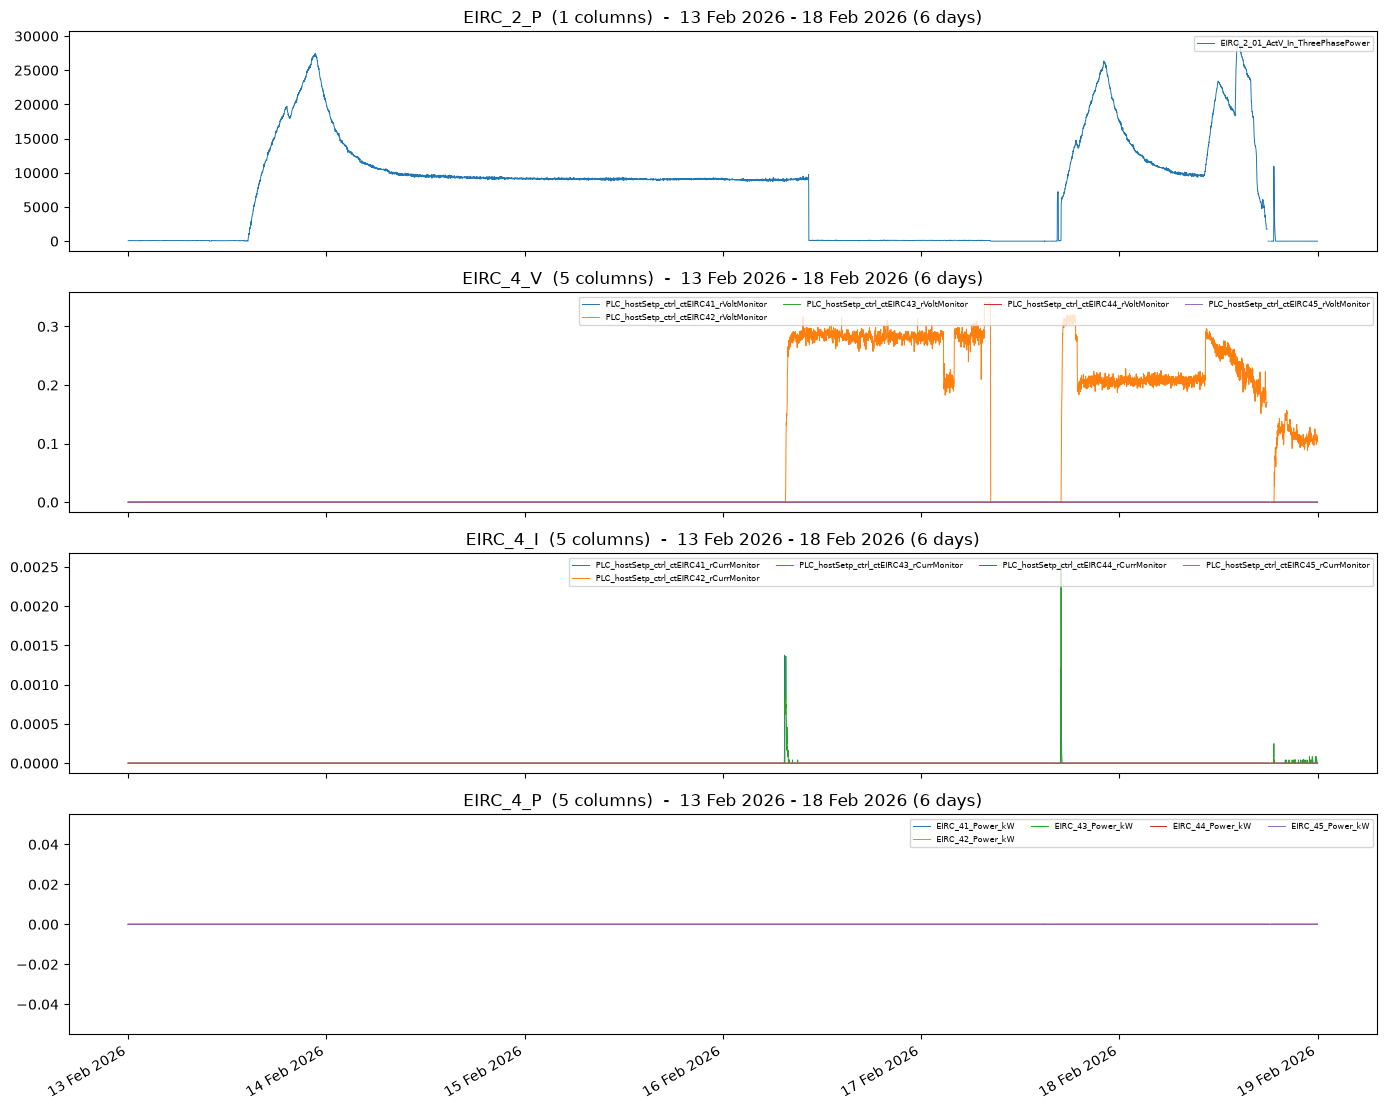

In [33]:
print(run_label(3))
plot_run(3)

### 01 Mar 2026 - 04 Mar 2026

01 Mar 2026 - 04 Mar 2026 (4 days)


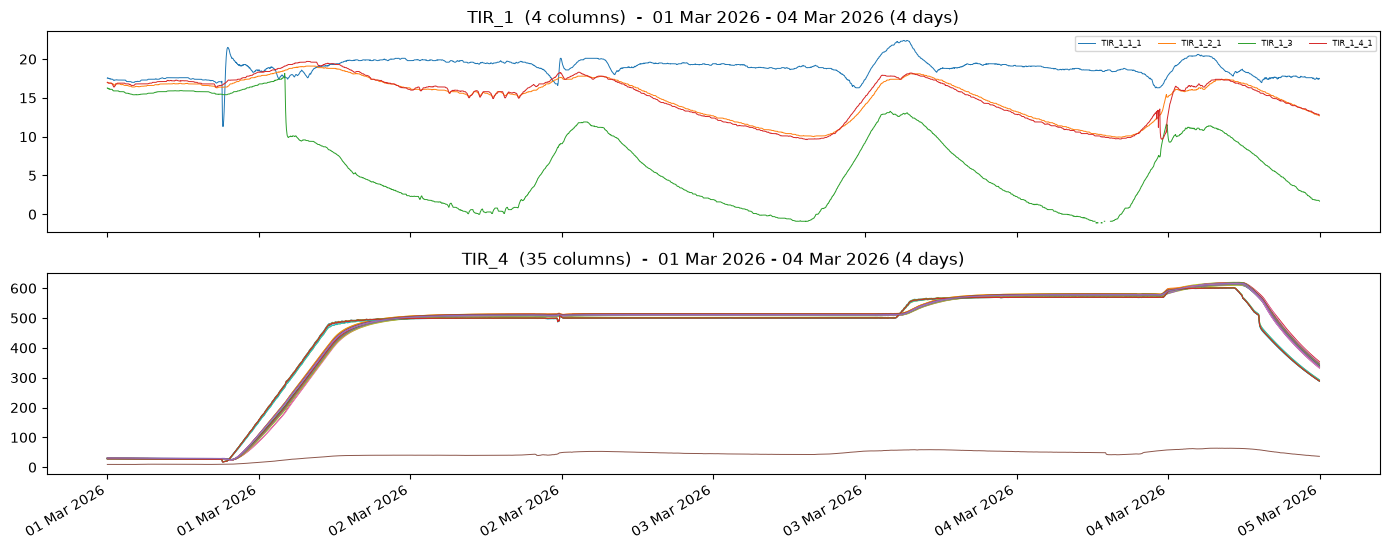

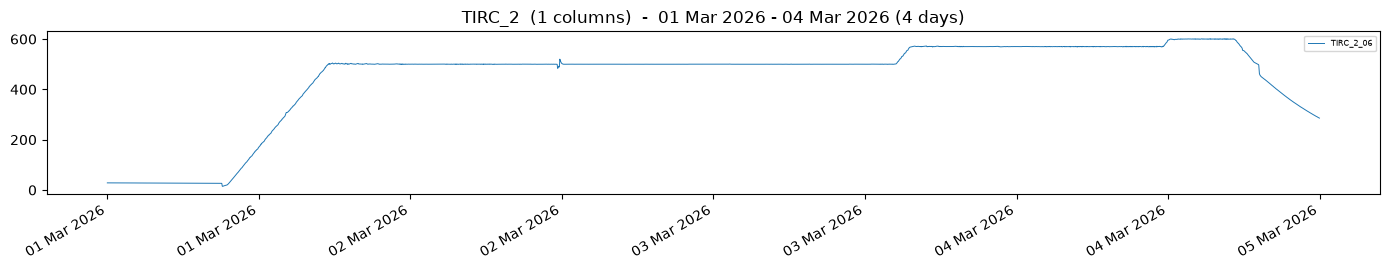

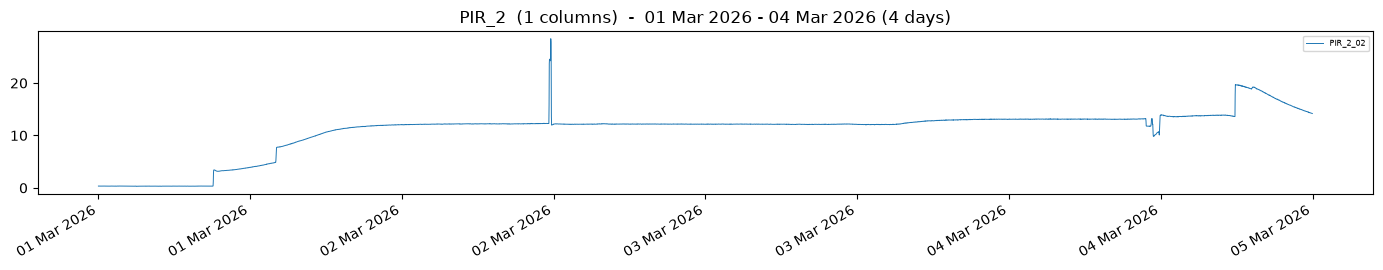

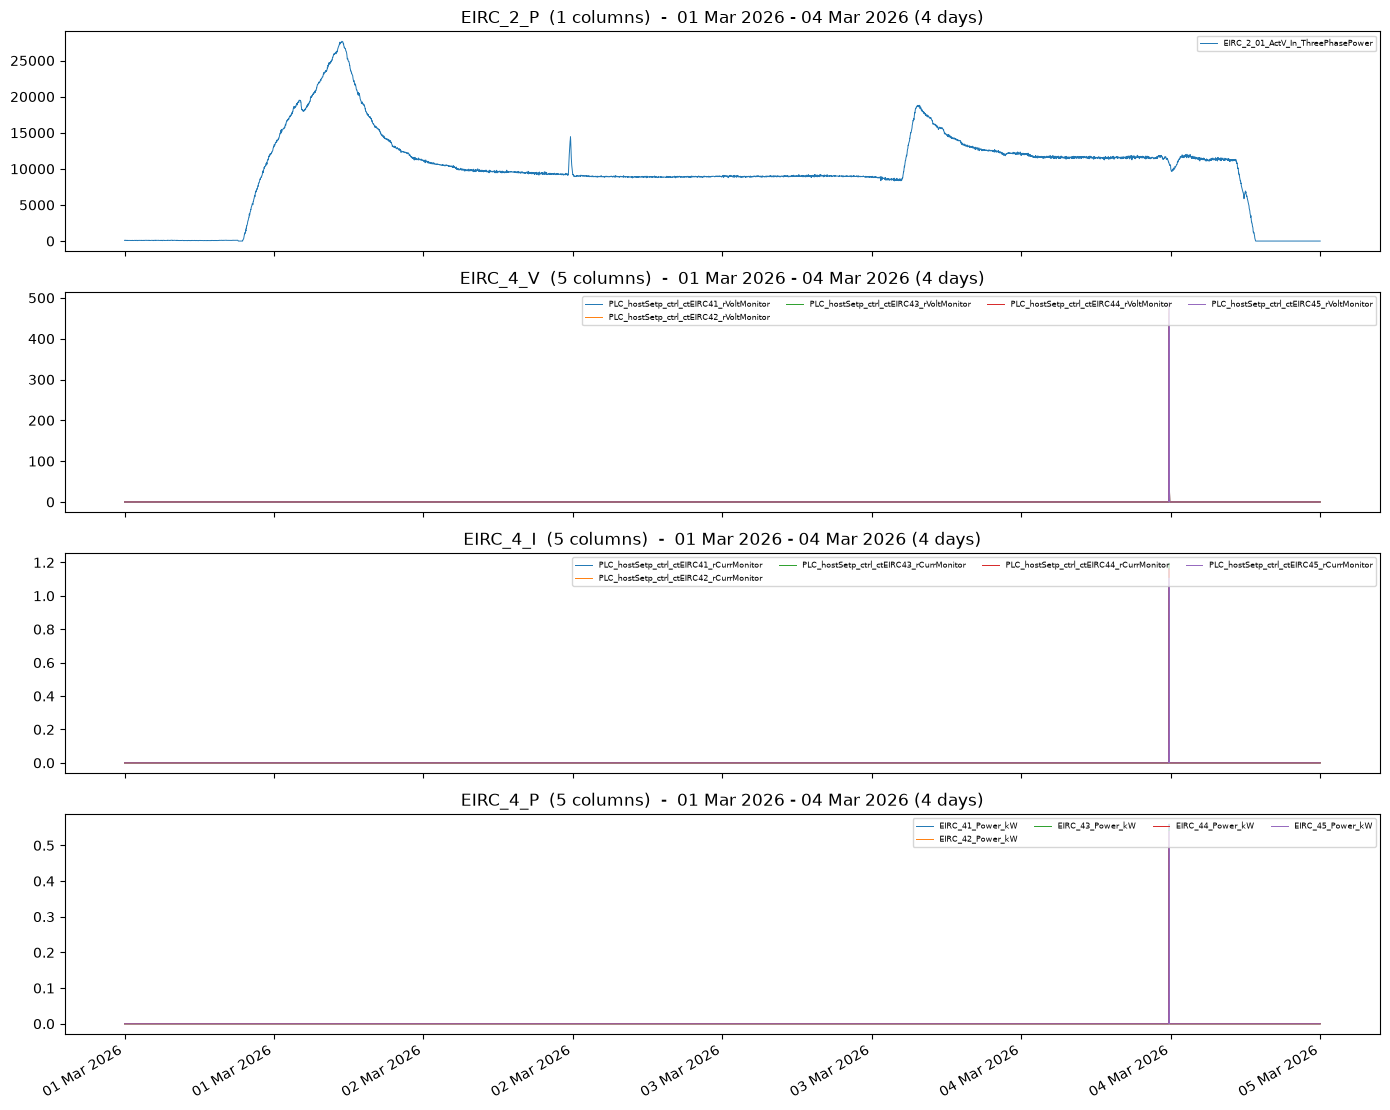

In [34]:
print(run_label(4))
plot_run(4)

### 12 Mar 2026 - 13 Mar 2026

12 Mar 2026 - 13 Mar 2026 (2 days)


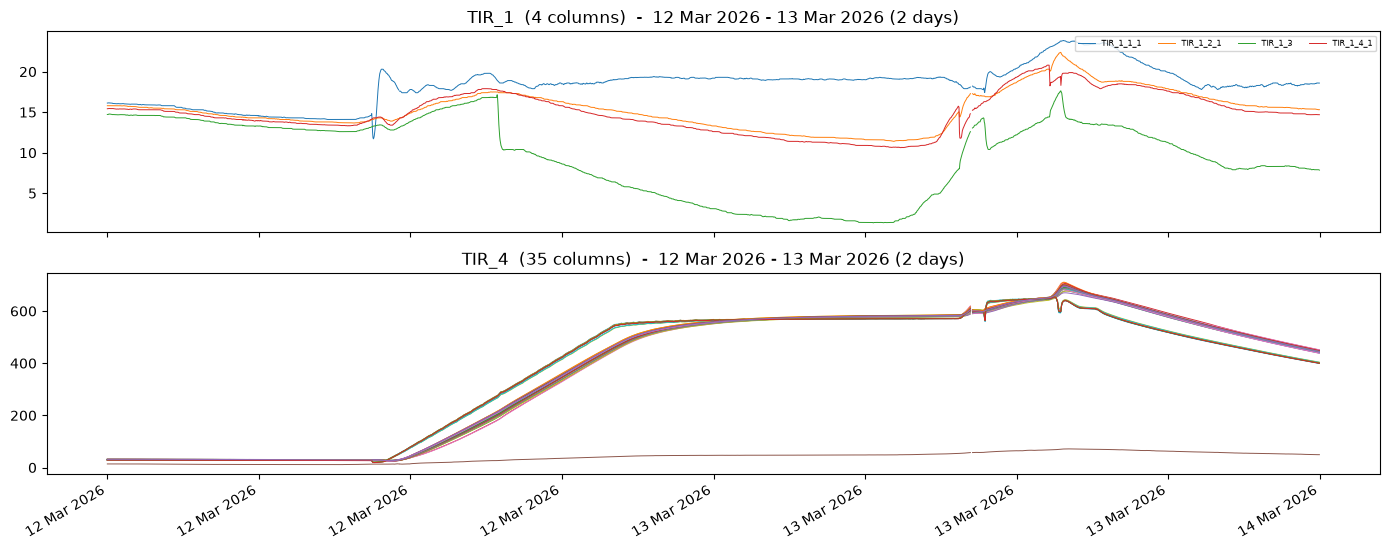

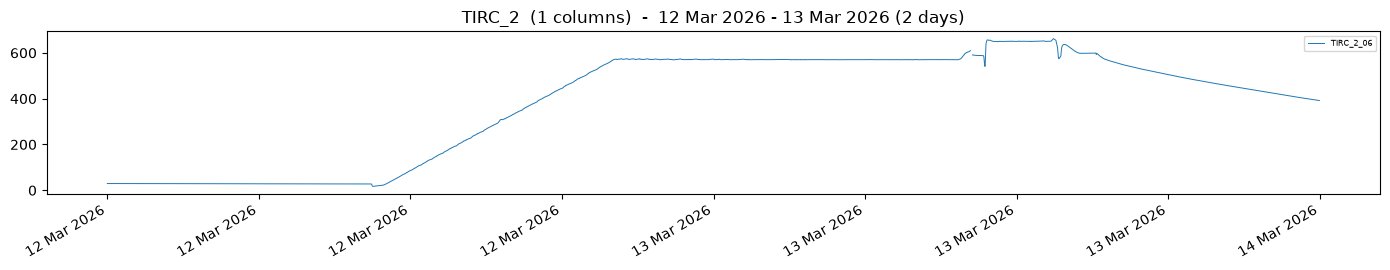

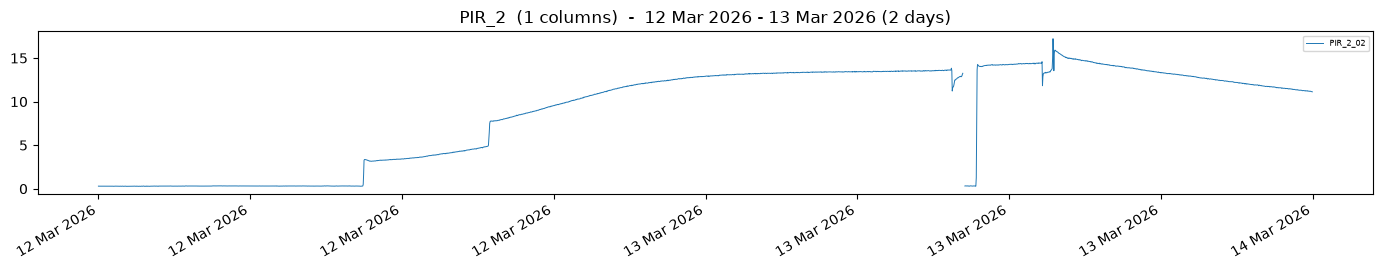

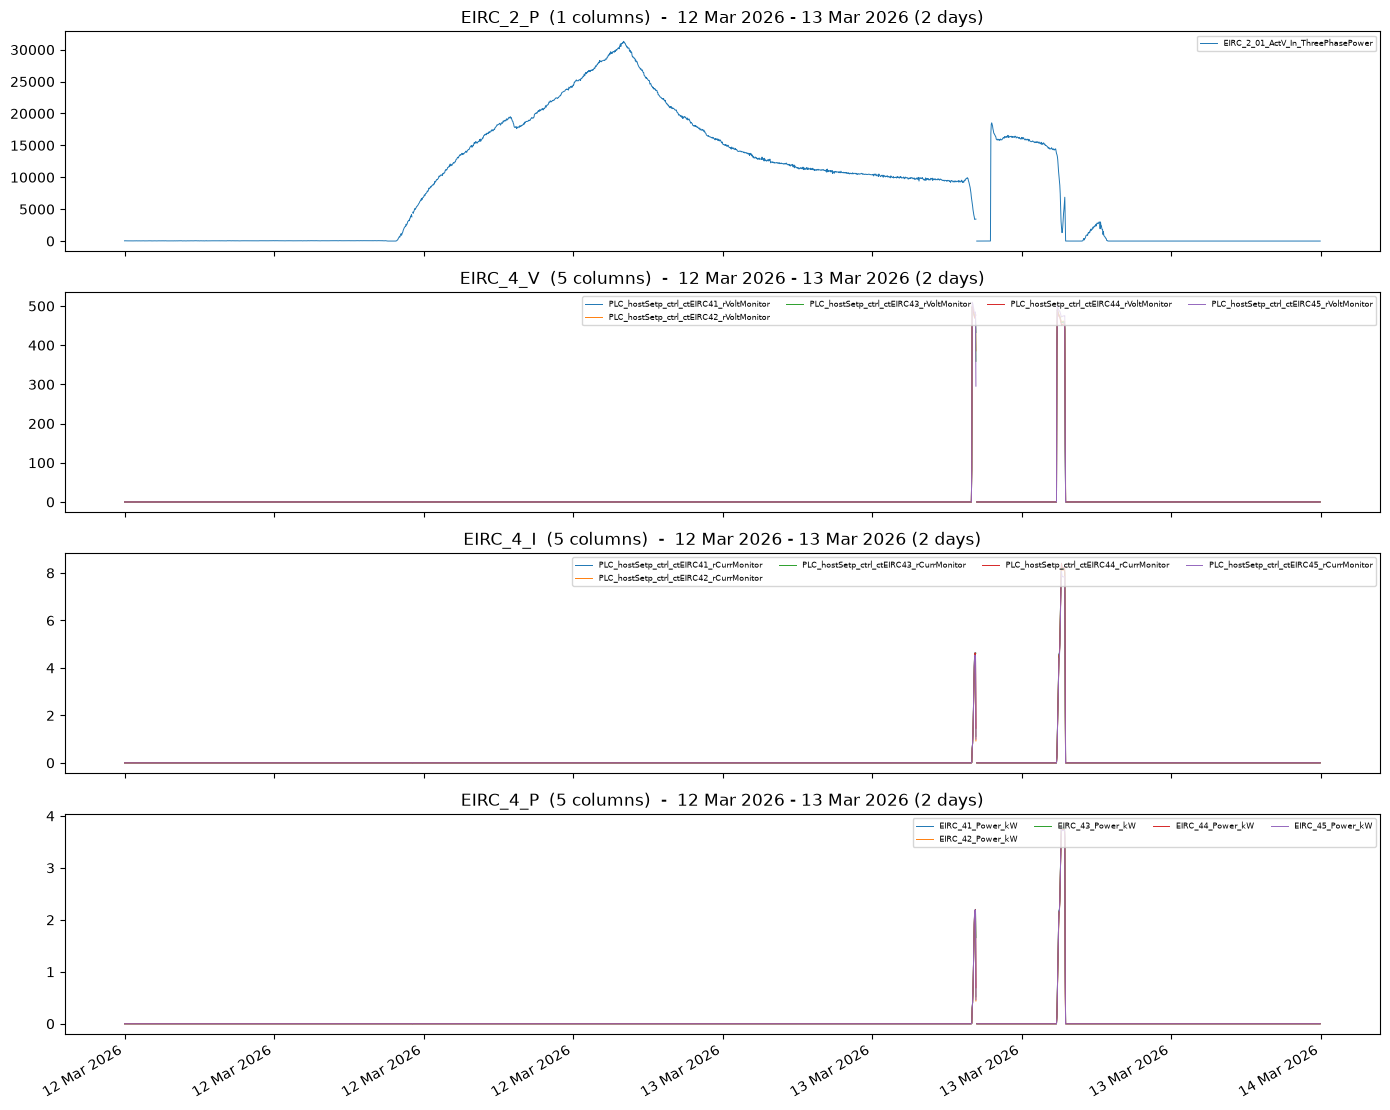

In [35]:
print(run_label(5))
plot_run(5)

### 17 Mar 2026 - 20 Mar 2026

17 Mar 2026 - 20 Mar 2026 (4 days)


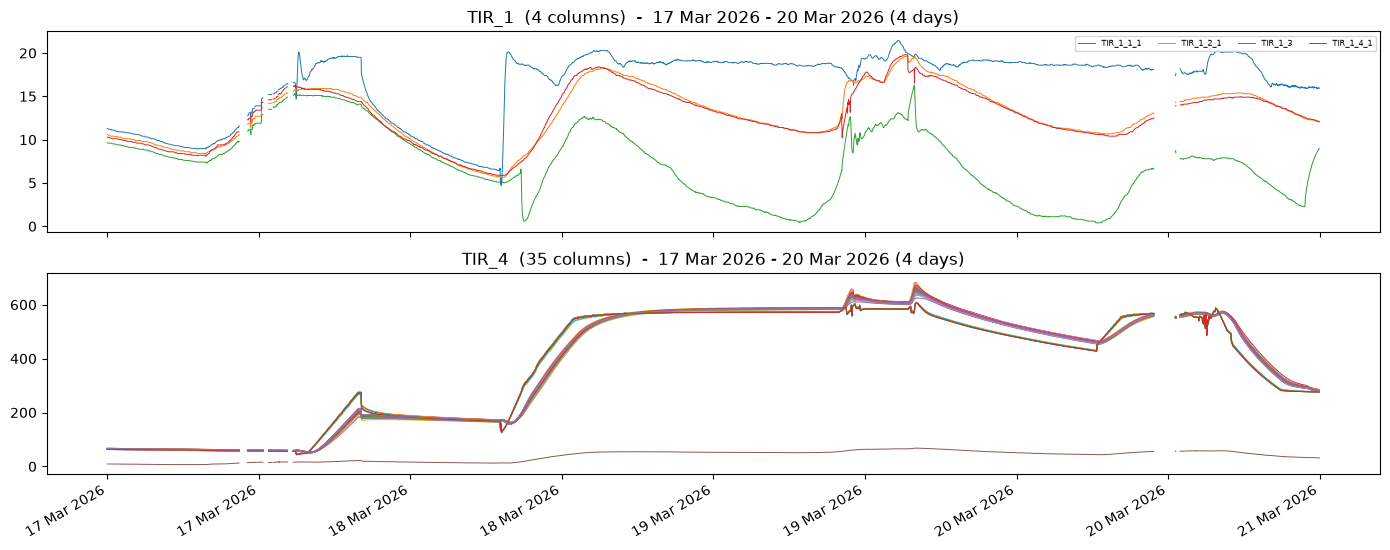

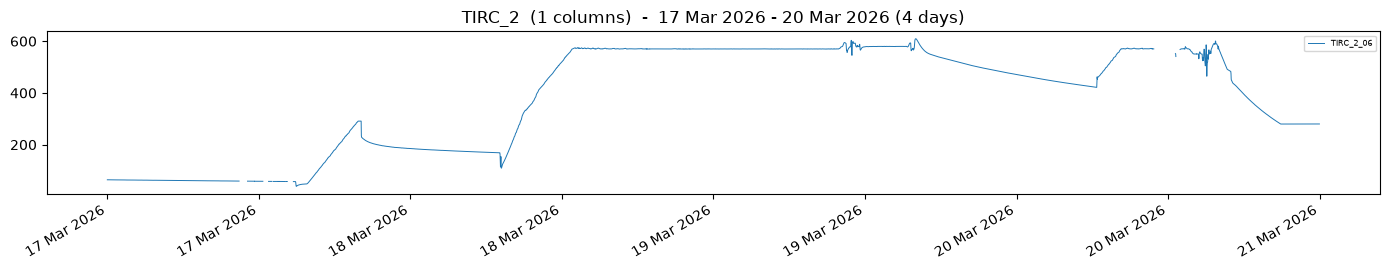

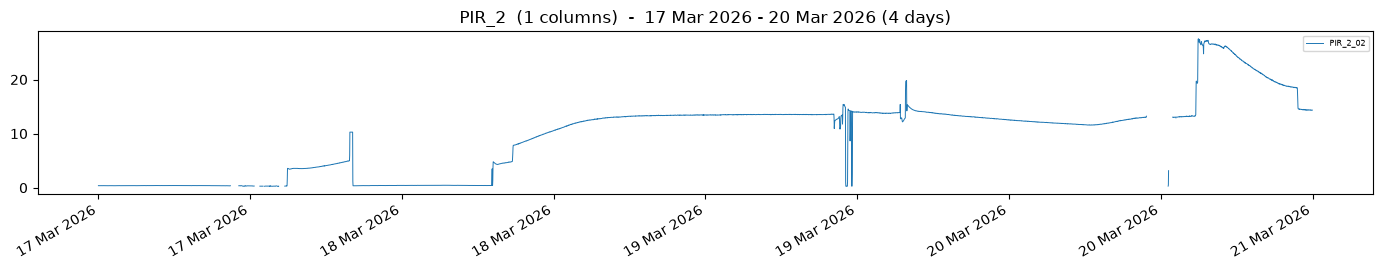

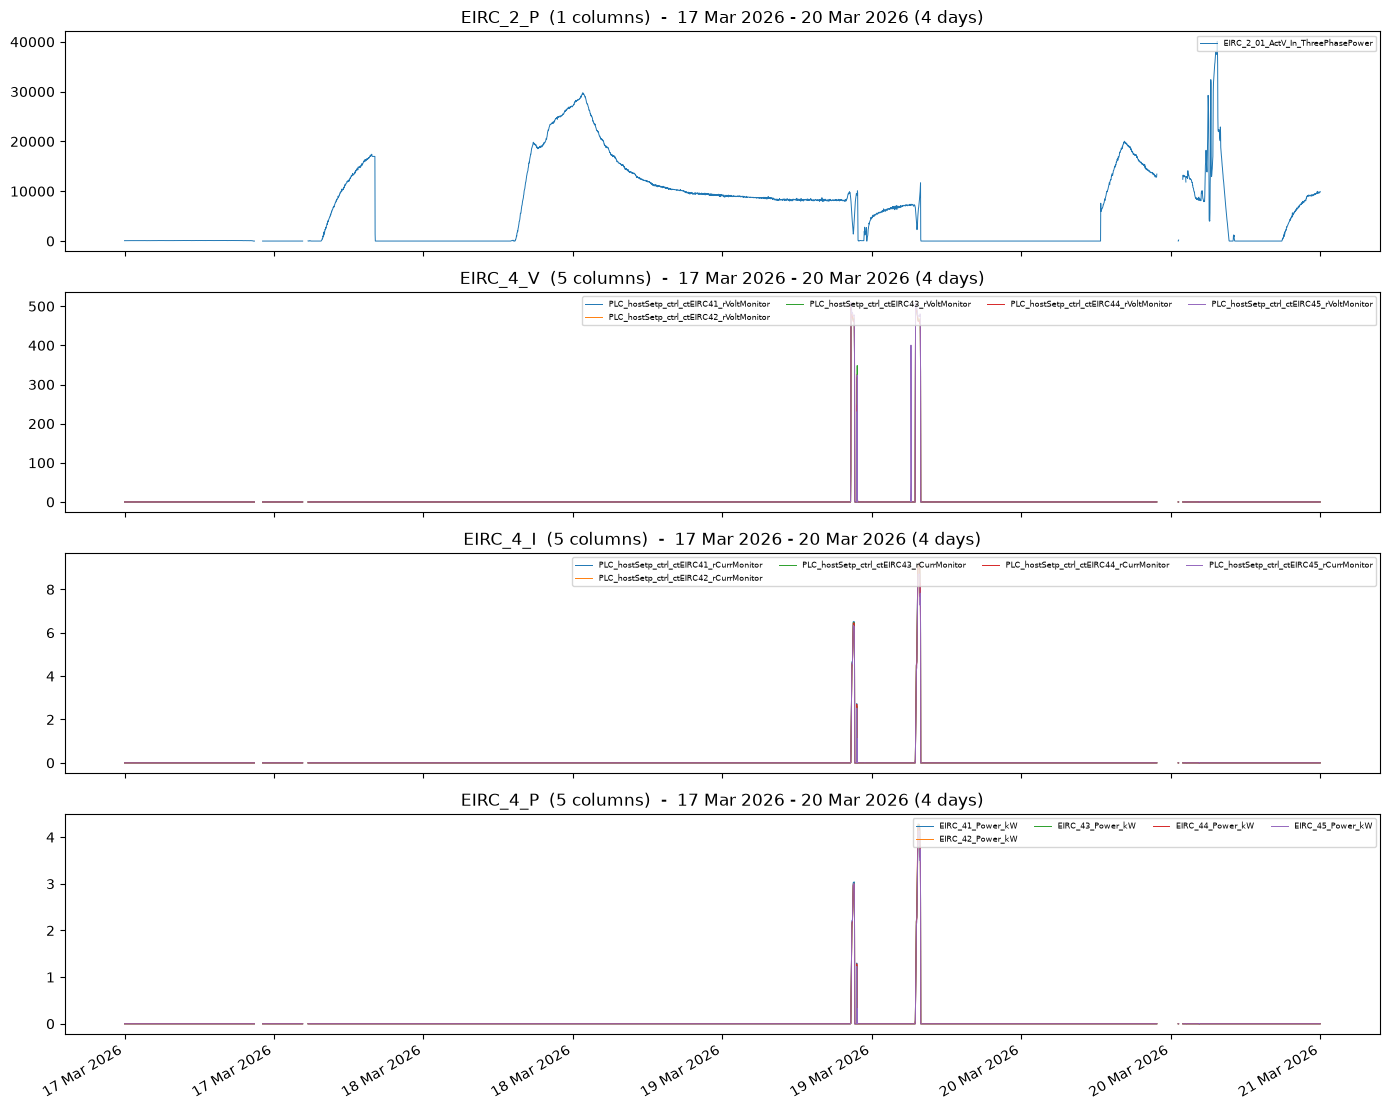

In [36]:
print(run_label(6))
plot_run(6)

### 22 Mar 2026 - 26 Mar 2026

22 Mar 2026 - 26 Mar 2026 (5 days)


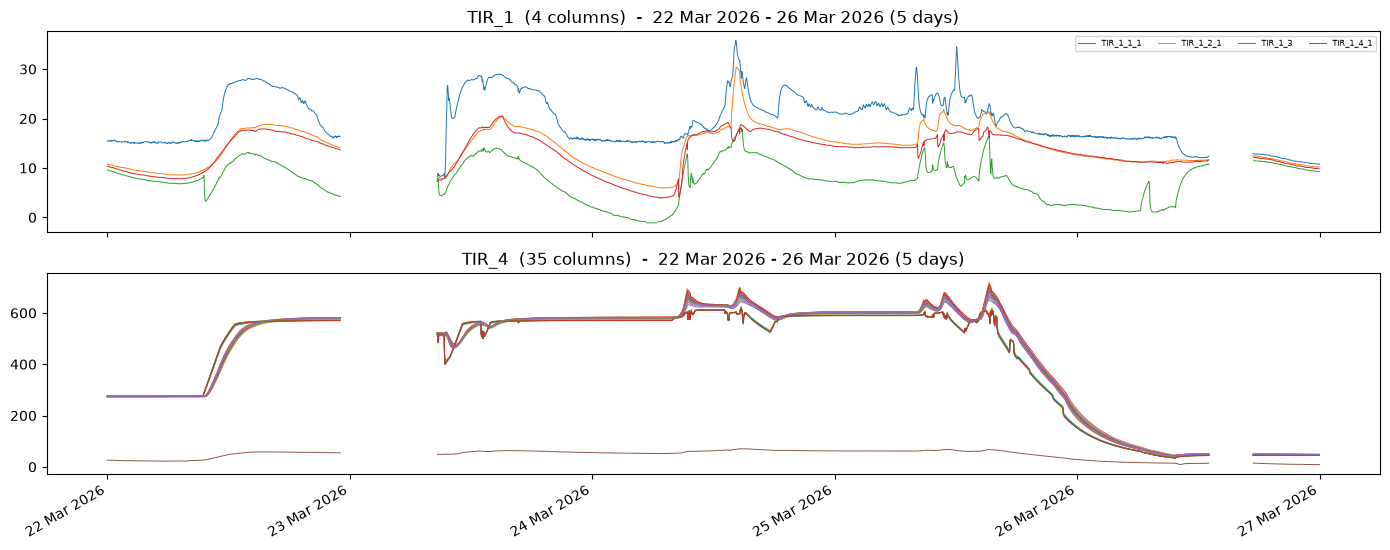

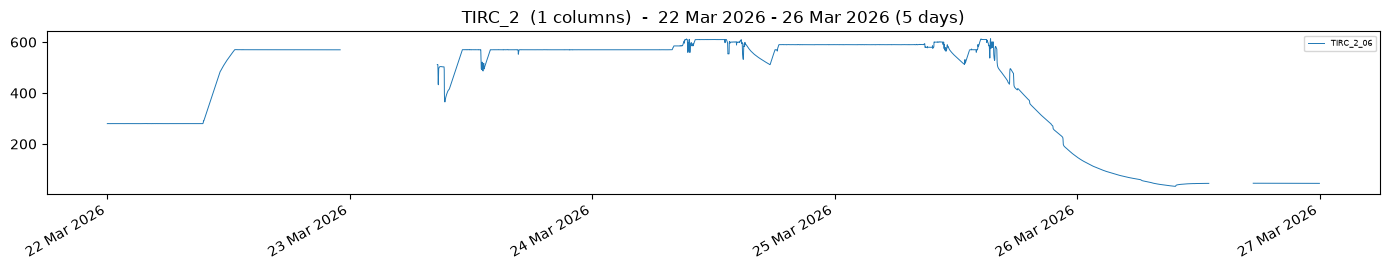

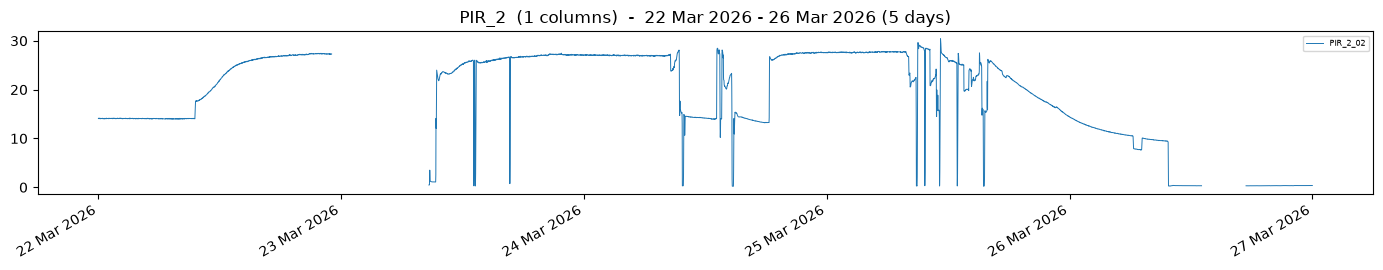

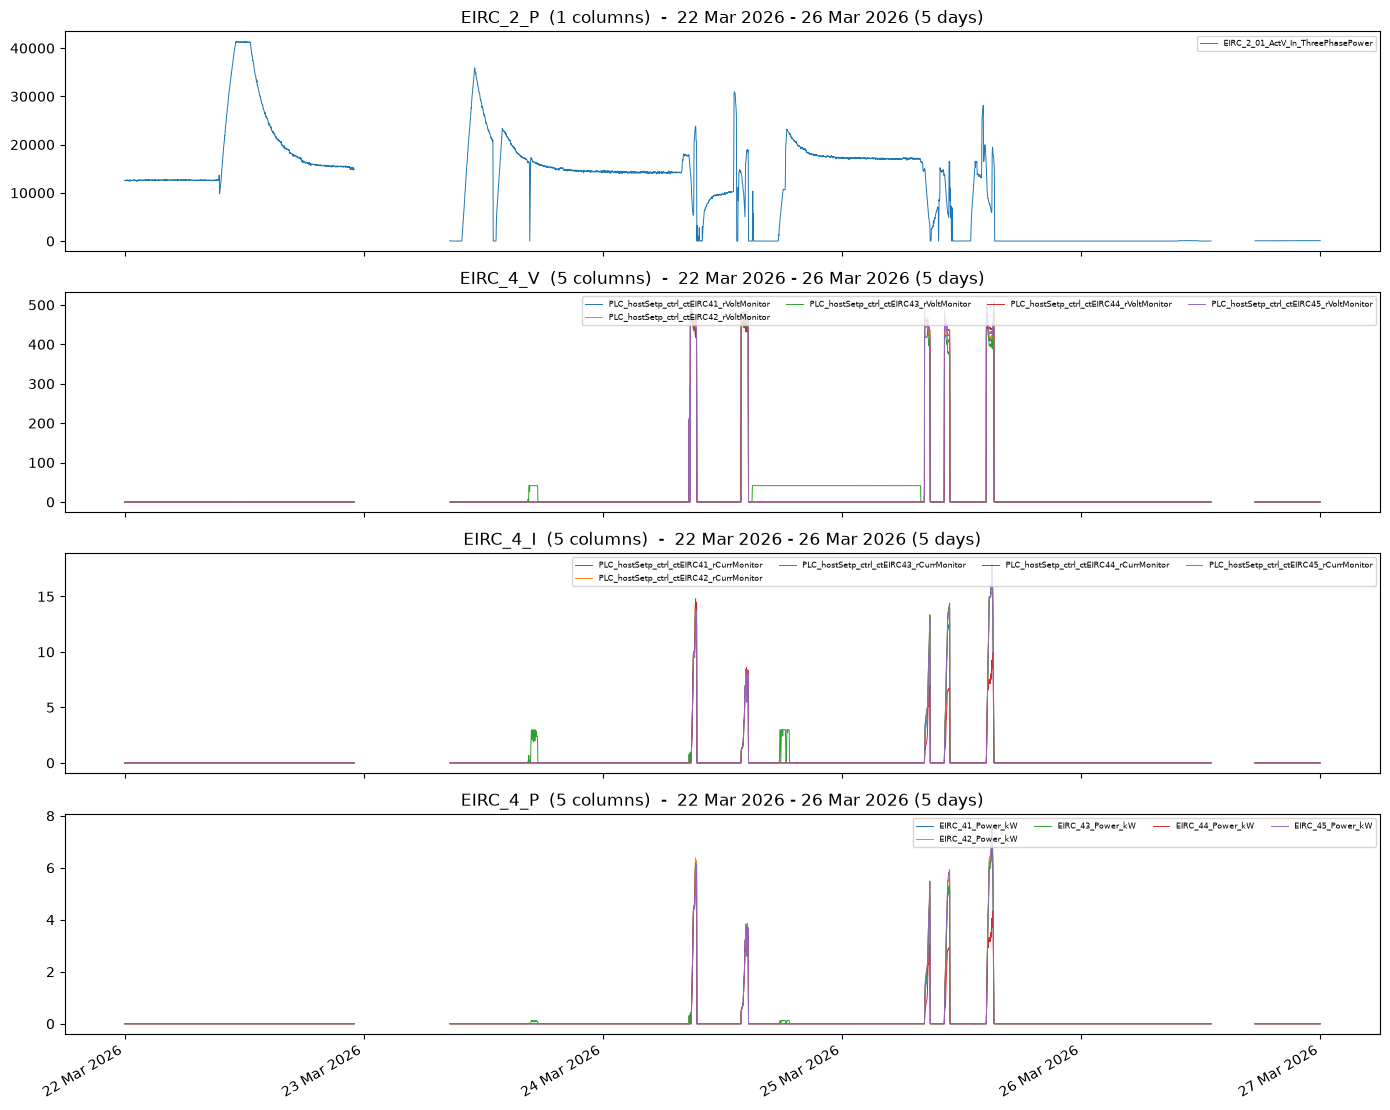

In [37]:
print(run_label(7))
plot_run(7)

### 28 Mar 2026 - 30 Mar 2026

28 Mar 2026 - 30 Mar 2026 (3 days)


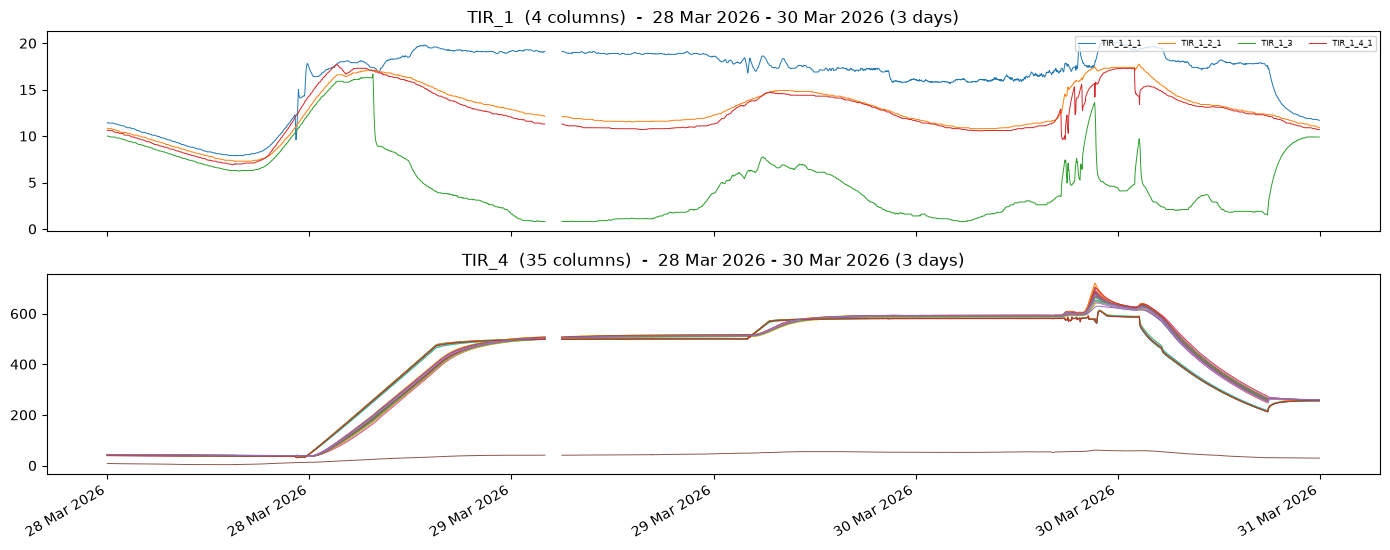

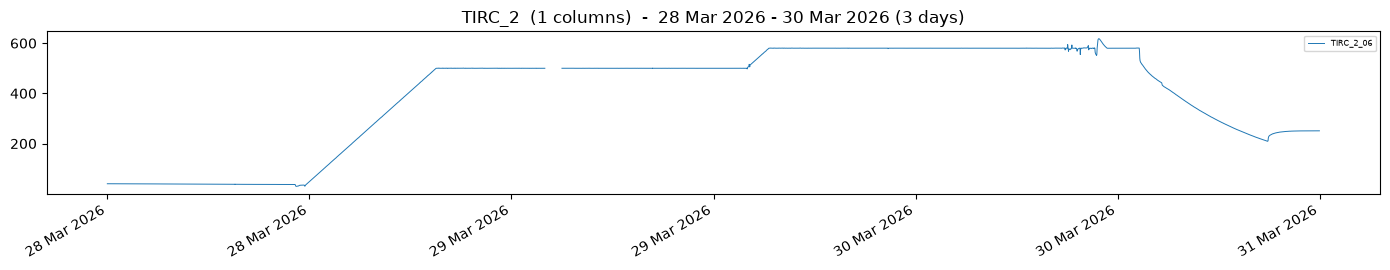

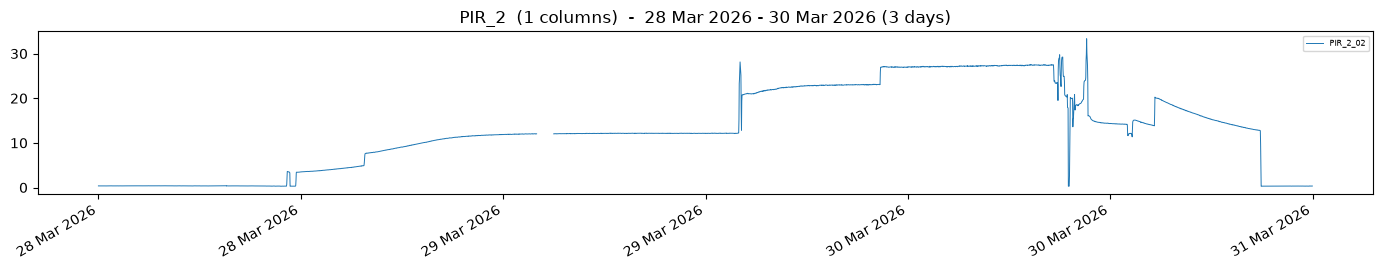

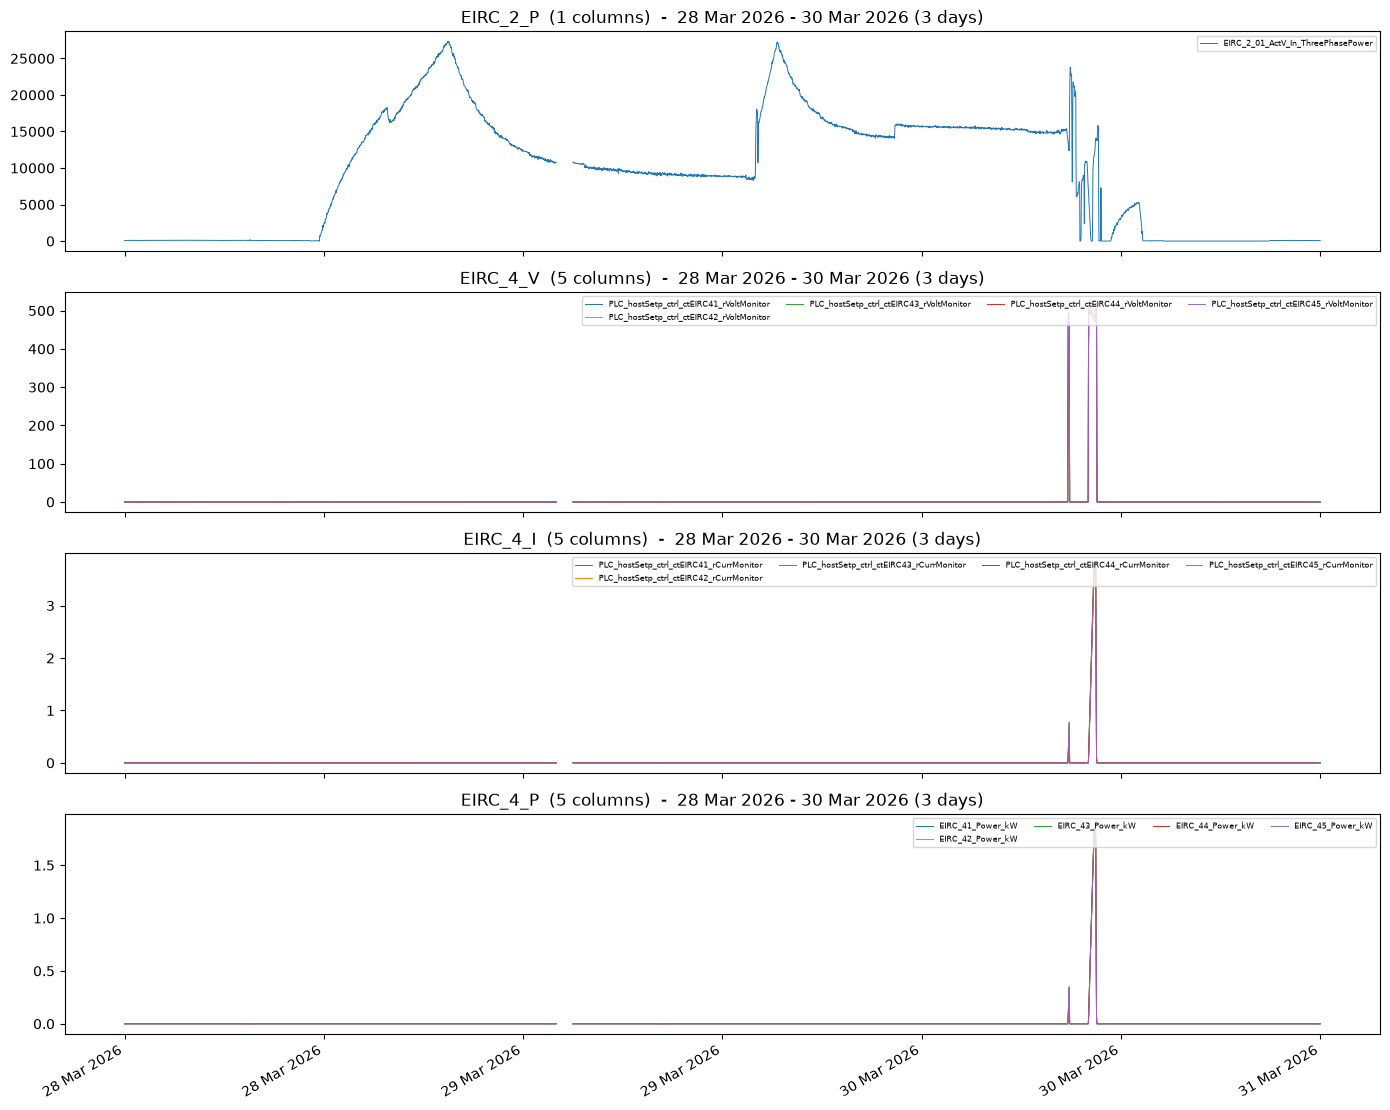

In [38]:
print(run_label(8))
plot_run(8)

## 9. Raw data split by stage

The 1 s raw data (`../02_data/parquet/<day>.parquet`, all 468 logger columns, values as delivered) is cut into
**one file per stage episode**, using the approved stage labels per minute
(`04_synthetic_data/library/traces_1min.parquet`, from `operating_states.py` → `build_library.py`).
Every 1 s row gets the `stage`, `sub_stage`, `operation`, `episode_id` and `file_id` of its minute.

**Shut-down is split by its two sub-stages**:
* **Cooling**: load to zero, forced or natural cooling, stack still warm;
* **At ambient (plant off)**: plant off and stack within 30 K of ambient, waiting for the next Start-up.

A Shut-down episode that holds both (3 of 19) is cut where the sub-stage changes, so each file holds one sub-stage only.

```
02_data/by_stage/
    1_Idle/  2_Start-up/  3_Hot_standby/  4_Thermal_adjustment/  5_Part_load/
        <episode_id>.parquet                  one episode, crossing midnight if it does
    7_Shut-down/
        1_Cooling/<episode_id>_cooling.parquet
        2_At_ambient/<episode_id>_at_ambient.parquet
    index.csv      one row per file: episode, sub-stage, start, end, hours, gap minutes, operations, rows, coverage, training flag, fold
    summary.csv    files, hours, rows and size per stage / sub-stage
```

The folder number follows `ops.STAGES`; there is no `6_Rated_power` because rated power never occurs.
Hours count labelled minutes only (logger gaps inside a file are in `gap_min`), as in `episodes.csv`.
Rows whose minute has no stage are left out. Some days log the same second twice with different
values (2026-03-01/02, 03-13); those rows are kept and counted in `dup_timestamps`.

Built by `python stage_split.py` (≈ 3 min, overwrites `by_stage/`). Run it again after any change to the stage labels
(`build_library.py` first).

In [ ]:
import stage_split

# stage_split.build()          # uncomment to rebuild by_stage/ from the parquet files
split_index = pd.read_csv(stage_split.OUT / "index.csv", parse_dates=["start", "end"], keep_default_na=False)
display(stage_split.summary())
split_index[["file_id", "stage", "sub_stage", "start", "end", "duration_h", "gap_min", "operations", "rows_1s",
             "dup_timestamps", "coverage_pct", "use_for_training", "fold"]]

Loading the split data: one stage (all files in time order), one Shut-down sub-stage, or one episode
(a Shut-down episode with both sub-stages comes back as one table), optionally only some columns.

In [ ]:
part_load = stage_split.load_stage("Part load", columns=STAGE_COLS)
print("Part load:", part_load.shape, part_load["episode_id"].nunique(), "episodes")

sd_cooling = stage_split.load_stage("Shut-down", ops.SD_COOLING, columns=STAGE_COLS)
sd_ambient = stage_split.load_stage("Shut-down", ops.SD_AMBIENT, columns=STAGE_COLS)
print("Shut-down / Cooling:", sd_cooling.shape, "  Shut-down / At ambient:", sd_ambient.shape)

ep = stage_split.load_episode("20251113_2132_Shut-down")   # Cooling, then At ambient
ep.groupby("sub_stage", sort=False)["Date Time"].agg(["first", "last", "size"])